# CardioRisk Studio — Pré-dépistage du risque de maladie coronarienne (Heart Disease UCI)

**Périmètre** : **pré-dépistage / triage uniquement** — prioriser les patients à examiner. Ce n'est **pas** un diagnostic (voir A1).

**Données** : UCI Heart Disease (Janosi, Steinbrunn, Pfisterer & Detrano, 1989 ; DOI 10.24432/C52P4X, licence CC BY 4.0). **920 lignes brutes → 918 patients** après retrait de 2 doublons exacts.

**Structure** : Partie A — cadrage (A1–A4) · Partie B — réalisation en 18 phases.

**Convention** : une cellule de code = une tâche, précédée de *Tâche / Pourquoi* et suivie d'une interprétation courte.

## Plan — 18 phases

| Phase | Contenu |
|---|---|
| 1 | Chargement du CSV (920 × 16) |
| 2 | Audit structurel : `info`, `describe`, modalités |
| 3 | Nettoyage : manquants, zéros invalides, doublons (→ 918 × 14) |
| 4 | Cible binaire `target`, familles `NUM` / `CAT` |
| 5 | Valeurs extrêmes (IQR) : détecter, décider |
| 6 | Analyse visuelle : distributions, boxplots, taux par modalité |
| 7 | Corrélation des 13 variables : Pearson + V de Cramér + eta |
| 8 | Split train / test stratifié (734 / 184) |
| 9 | Préparation apprise sur le train : médiane, mode, scaling, one-hot |
| 10 | 3 stratégies de valeurs manquantes |
| 11 | Comparaison de modèles (5, puis 8 familles) |
| 12 | Évaluation test : rapport, R²/MAE/MSE, confusion, ROC |
| 13 | Seuil de décision (rappel ≥ 90 %) |
| 14 | Contrôle visuel réel vs prédit |
| 15 | Importance des variables (permutation) |
| 16 | Prédiction sur nouvelles données |
| 17 | Export `model.joblib` + `model_meta.json` |
| 18 | Conclusion, réponses Q1–Q5, limites |

**Règle d'ordre** : nettoyage (3, 5) → visuel (6) → corrélation (7). Imputation, encodage et scaling viennent **après le split**, appris sur le train : c'est de la préparation, pas du nettoyage (aucune fuite).

## A1. Contexte et périmètre

Les maladies cardiovasculaires sont une cause majeure de mortalité. À partir de données cliniques simples (âge, tension, cholestérol, fréquence cardiaque maximale, symptômes, résultats d'examen), on cherche à **repérer tôt** les patients à orienter vers un examen complémentaire.

| Terme | Définition | Dans ce projet |
|---|---|---|
| **Dépistage** | Tester une population pour repérer les personnes probablement malades | objectif général |
| **Pré-dépistage / triage** | Filtre rapide en amont qui **priorise** qui doit être vu d'abord | **seul objet du projet** |
| **Diagnostic** | Acte médical de confirmation, par un professionnel de santé | **hors périmètre** |

**Conséquence** : le modèle produit une **probabilité de risque** et une **priorité**, jamais une conclusion médicale. En pré-dépistage, rater un malade coûte plus cher qu'une fausse alerte : on privilégie le **rappel** (Phases 12–13).

Dataset : **4 centres** (Cleveland, Hongrie, Suisse, VA Long Beach), données de 1988, 13 variables explicatives.

## A2. Problématique

**Question** : à partir de 13 variables cliniques, peut-on estimer la probabilité qu'un patient présente une maladie coronarienne (rétrécissement > 50 %) avec une fiabilité suffisante pour **prioriser** les examens ?

- **Q1** — Quels facteurs sont associés à la maladie ?
- **Q2** — Quelles variables contribuent le plus à la prédiction ?
- **Q3** — Quelle est la capacité prédictive du modèle ?
- **Q4** — Quel modèle et quelle stratégie de valeurs manquantes retenir ?
- **Q5** — Quel seuil de décision pour limiter les malades manqués ?

## A3. Processus suivi

Dix étapes génériques, déclinées en 18 phases : données brutes → nettoyage → EDA → split → pipeline → comparaison de modèles → évaluation → seuil → importance → export.


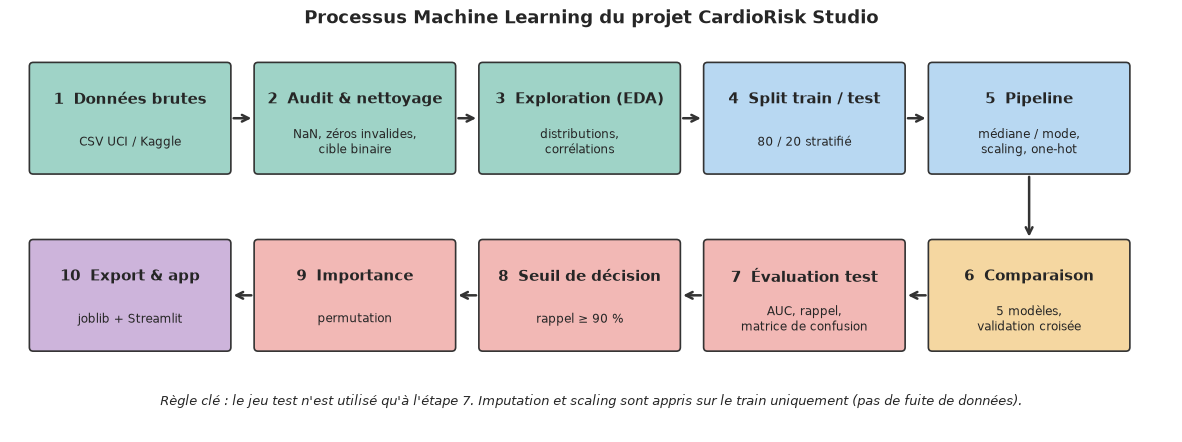

In [106]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ("1  Données brutes", "CSV UCI / Kaggle"),
    ("2  Audit & nettoyage", "NaN, zéros invalides,\ncible binaire"),
    ("3  Exploration (EDA)", "distributions,\ncorrélations"),
    ("4  Split train / test", "80 / 20 stratifié"),
    ("5  Pipeline", "médiane / mode,\nscaling, one-hot"),
    ("6  Comparaison", "5 modèles,\nvalidation croisée"),
    ("7  Évaluation test", "AUC, rappel,\nmatrice de confusion"),
    ("8  Seuil de décision", "rappel ≥ 90 %"),
    ("9  Importance", "permutation"),
    ("10  Export & app", "joblib + Streamlit"),
]
colors = ["#9FD3C7", "#9FD3C7", "#9FD3C7", "#B8D8F2", "#B8D8F2", "#F5D7A1", "#F2B8B5", "#F2B8B5", "#F2B8B5", "#CDB4DB"]

fig, ax = plt.subplots(figsize=(15, 5.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 5.2); ax.axis("off")
w, h = 2.5, 1.35
pos = [(0.3 + i * 2.9, 3.4) for i in range(5)] + [(0.3 + (4 - i) * 2.9, 1.1) for i in range(5)]
for (x, y), (t, s), c in zip(pos, steps, colors):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=c, ec="#333", lw=1.2))
    ax.text(x + w/2, y + h*0.68, t, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w/2, y + h*0.27, s, ha="center", va="center", fontsize=8.5)
for i in range(9):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if i < 4:   a, b = (x1 + w + 0.05, y1 + h/2), (x2 - 0.05, y2 + h/2)
    elif i == 4: a, b = (x1 + w/2, y1 - 0.05), (x2 + w/2, y2 + h + 0.05)
    else:       a, b = (x1 - 0.05, y1 + h/2), (x2 + w + 0.05, y2 + h/2)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.8, color="#333"))
ax.text(7.5, 0.35, "Règle clé : le jeu test n'est utilisé qu'à l'étape 7. Imputation et scaling sont appris sur le train uniquement (pas de fuite de données).",
        ha="center", fontsize=9.5, style="italic")
plt.title("Processus Machine Learning du projet CardioRisk Studio", fontsize=13, weight="bold")
plt.show()

## A4. Attributs techniques

13 variables explicatives + 1 cible (`target`). Noms du CSV Kaggle : la fréquence cardiaque maximale est `thalch` (`thalach` dans UCI).

| Variable | Signification | Famille | Type | Préparation |
|---|---|---|---|---|
| `age` | Âge | Démographique | Numérique | médiane + scaling |
| `sex` | Sexe | Démographique | Catégorielle (2) | mode + one-hot |
| `cp` | Type de douleur thoracique | Symptôme | Catégorielle (4) | mode + one-hot |
| `trestbps` | Tension artérielle au repos (mmHg) | Mesure | Numérique | médiane + scaling |
| `chol` | Cholestérol (mg/dL) | Mesure | Numérique | médiane + scaling |
| `fbs` | Glycémie à jeun > 120 mg/dL | Mesure | Catégorielle (2) | mode + one-hot |
| `restecg` | Résultat ECG au repos | Examen | Catégorielle (3) | mode + one-hot |
| `thalch` | Fréquence cardiaque maximale | Examen | Numérique | médiane + scaling |
| `exang` | Angine induite par l'effort | Symptôme | Catégorielle (2) | mode + one-hot |
| `oldpeak` | Dépression ST à l'effort | Examen | Numérique | médiane + scaling |
| `slope` | Pente du segment ST | Examen | Catégorielle (3) | mode + one-hot |
| `ca` | Nombre de vaisseaux colorés (0–3) | Examen | Numérique (discret) | médiane + scaling + indicateur |
| `thal` | Résultat de scintigraphie | Examen | Catégorielle (3) | mode + one-hot |
| `num` → `target` | Diagnostic 0–4 recodé en 0 / 1 | Cible | Binaire | — |

### Glossaire des métriques

| Terme | Sens | Lecture |
|---|---|---|
| **AUC** (ROC-AUC) | Probabilité que le modèle note un malade plus haut qu'un sain, tous seuils confondus | 0,5 = hasard ; 1 = parfait |
| **CV** (validation croisée) | Le train est coupé en 5 plis ; chacun sert une fois de validation | plus stable qu'un seul split |
| **Rappel** | Malades détectés / malades réels | prioritaire en pré-dépistage |
| **Précision** | Vrais malades parmi les patients signalés | limite les fausses alertes |
| **Seuil** | Probabilité à partir de laquelle on déclare « à risque » | 0,50 par défaut ; ici calculé (Phase 13) |

## Partie B — Réalisation

## Phase 1 — Chargement

**Tâche** : importer les bibliothèques puis lire `heart_disease_uci.csv` dans `df`.
**Pourquoi** : on travaille sur une copie en mémoire, le fichier source reste intact.


In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

**Comment lire ce fichier depuis le lien GitHub ?**

Le lien `https://github.com/.../blob/main/heart_disease_uci.csv` est une **page HTML** : `pd.read_csv` y verrait du HTML, pas du CSV. Il faut la version **raw** (`raw.githubusercontent.com/...`) qui renvoie le fichier brut. Le code ci-dessous tente le lien raw et **retombe sur la copie locale** si le réseau est absent, ce qui rend le notebook reproductible dans les deux cas.

In [108]:
# Lecture des données : le lien GitHub "blob" affiche la page web, il faut la version "raw"
URL_CSV = "https://raw.githubusercontent.com/bennoomenfaker/cardiorisk-studio/main/heart_disease_uci.csv"

try:
    df = pd.read_csv(URL_CSV)                    # lecture directe depuis GitHub
    origine = "GitHub (raw)"
except Exception:                                # hors ligne ou fichier renommé
    df = pd.read_csv("heart_disease_uci.csv")    # copie locale du dépôt
    origine = "fichier local"

print("Source :", origine, "| dimensions :", df.shape)

Source : GitHub (raw) | dimensions : (920, 16)


**Interprétation** : `(920, 16)` = **920 lignes brutes** × 16 colonnes (`id`, `dataset`, 13 variables, `num`).

⚠️ **920 ou 918 ?** 920 = lignes du fichier CSV ; **918 = patients** après retrait des **2 doublons exacts** en Phase 3. Tout le reste du notebook travaille sur 918.


In [109]:
df.head() 


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**Interprétation** : une ligne = un patient ; colonnes numériques et texte mélangées → un audit des types est nécessaire.

## Phase 2 — Audit structurel

**Tâche** : décrire les données sans rien modifier (`info`, `describe`, effectifs des modalités).
**Pourquoi** : connaître types, échelles et valeurs manquantes avant toute décision.


In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


**Interprétation** : colonnes complètes (`age`, `sex`, `cp`, `num`…) ; colonnes très incomplètes : `ca` (309 valeurs), `thal` (434), `slope` (611).


In [111]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


**Interprétation** : `chol` minimum 0 et `trestbps` minimum 0 sont **impossibles** → manquants déguisés (corrigés en 3.1). `oldpeak` négatif est plausible. `age` : 28–77 ans, moyenne 53,5.


In [112]:
df.describe(include=["object", "str"])


,sex,dataset,cp,fbs,restecg,exang,slope,thal
count,920,920,920,830,918,865,611,434
unique,2,4,4,2,3,2,3,3
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal
freq,726,304,496,692,551,528,345,196


In [113]:
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())

sex -> {'Male': 726, 'Female': 194}
cp -> {'asymptomatic': 496, 'non-anginal': 204, 'atypical angina': 174, 'typical angina': 46}
fbs -> {False: 692, True: 138, nan: 90}
restecg -> {'normal': 551, 'lv hypertrophy': 188, 'st-t abnormality': 179, nan: 2}
exang -> {False: 528, True: 337, nan: 55}
slope -> {'flat': 345, nan: 309, 'upsloping': 203, 'downsloping': 63}
thal -> {nan: 486, 'normal': 196, 'reversable defect': 192, 'fixed defect': 46}


**Interprétation** : `sex` 79 % masculin ; 4 centres (Cleveland le plus gros, 304) ; `cp = asymptomatic` majoritaire (496) ; `thal` et `slope` très incomplets.

## Phase 3 — Nettoyage de base (avant visuel et corrélation)

| Étape | Action |
|---|---|
| 3.0 | Diagnostiquer les valeurs manquantes |
| 3.1 | Remplacer les valeurs impossibles (`chol = 0`, `trestbps = 0`) par `NaN` |
| 3.2 | **Harmoniser les modalités catégorielles** (espaces, casse, libellés) |
| 3.3 | Supprimer les colonnes inutiles (`id`, `dataset`) et les doublons exacts |

L'imputation n'est **pas** faite ici : elle est apprise après le split (Phase 9).


In [114]:
tableau = pd.DataFrame({
    "manquants": df.isna().sum(),
    "% manquants": (df.isna().mean() * 100).round(1)
})
tableau[tableau["manquants"] > 0].sort_values("% manquants", ascending=False)

,manquants,% manquants
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


### 3.0 — Valeurs manquantes

| Variable | Manquants | % |
|---|---:|---:|
| `ca` | 611 | 66,4 % |
| `thal` | 486 | 52,8 % |
| `slope` | 309 | 33,6 % |
| `fbs` | 90 | 9,8 % |
| `oldpeak` | 62 | 6,7 % |
| `trestbps` | 59 | 6,4 % |
| `exang` | 55 | 6,0 % |
| `thalch` | 55 | 6,0 % |
| `chol` | 30 | 3,3 % |
| `restecg` | 2 | 0,2 % |

**Décision** : aucune ligne n'est supprimée (on perdrait presque tout) et `ca`/`thal` sont des examens utiles → **imputation** dans le pipeline (Phase 9) avec indicateur de manquant ; 3 stratégies comparées en Phase 10.

**Tâche** : remplacer `chol = 0` et `trestbps = 0` par `NaN` (manquants déguisés).
**Pourquoi** : ces valeurs n'existent pas chez un patient vivant.


In [115]:
print("chol = 0       :", (df["chol"] == 0).sum())
print("trestbps = 0   :", (df["trestbps"] == 0).sum())

df["chol"] = df["chol"].replace(0, np.nan)
df["trestbps"] = df["trestbps"].replace(0, np.nan)

print("Manquants chol après correction     :", df["chol"].isna().sum())
print("Manquants trestbps après correction :", df["trestbps"].isna().sum())

chol = 0       : 172
trestbps = 0   : 1
Manquants chol après correction     : 202
Manquants trestbps après correction : 60


### 3.2 — Harmonisation des variables catégorielles

**Tâche** : vérifier et normaliser les modalités (`" Male"` / `"male"`, espaces doubles) **avant** les graphiques et la corrélation.
**Pourquoi** : deux écritures d'une même catégorie créeraient deux modalités distinctes → barres fausses, moyennes biaisées et colonnes One-Hot inutiles.


In [116]:
# 1) Libellés : espaces parasites supprimés ; True/False passés en texte ; NaN conservés
CAT_STR = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
for col in CAT_STR:
    df[col] = df[col].map(lambda v: np.nan if pd.isna(v) else " ".join(str(v).split()))

# 2) Audit des modalités : combien, lesquelles, part de manquants, modalité la plus rare, doublons de casse
audit_cat = pd.DataFrame({
    "modalités": {c: ", ".join(sorted(df[c].dropna().astype(str).unique())) for c in CAT_STR},
    "nb": {c: df[c].nunique() for c in CAT_STR},
    "% manquants": {c: round(df[c].isna().mean() * 100, 1) for c in CAT_STR},
    "modalité la plus rare (%)": {c: round(df[c].value_counts(normalize=True).min() * 100, 1) for c in CAT_STR},
    "doublon de casse": {c: df[c].dropna().astype(str).str.lower().nunique() < df[c].nunique() for c in CAT_STR},
})
audit_cat

,modalités,nb,% manquants,modalité la plus rare (%),doublon de casse
sex,"Female, Male",2,0.0,21.1,False
cp,"asymptomatic, atypical angina, non-anginal, ty...",4,0.0,5.0,False
fbs,"False, True",2,9.8,16.6,False
restecg,"lv hypertrophy, normal, st-t abnormality",3,0.2,19.5,False
exang,"False, True",2,6.0,39.0,False
slope,"downsloping, flat, upsloping",3,33.6,10.3,False
thal,"fixed defect, normal, reversable defect",3,52.8,10.6,False


**Interprétation** : `doublon de casse = False` partout et aucun espace parasite → **aucune correction n'a été nécessaire**. Les modalités rares existent (`cp = typical angina` 5 %, `slope = downsloping` 10 %) mais restent exploitables : on les garde, un One-Hot les traite sans les fusionner.

Le libellé `reversable defect` est conservé tel quel (orthographe du fichier source, attendue par `model_meta.json` et par l'application).

**Interprétation** : 172 patients avaient `chol = 0`, 1 avait `trestbps = 0` ; manquants `chol` 30 → 202, `trestbps` 59 → 60.


**Tâche** : vérifier si les manquants sont répartis au hasard entre les 4 centres.
**Pourquoi** : si une variable n'est mesurée que dans un hôpital, son association avec la maladie ne vaut que pour cet hôpital.

In [117]:
# Valeurs réellement observées par centre (le dataset n'est pas encore retiré)
df.groupby("dataset")[["ca", "thal", "slope"]].count().assign(patients=df["dataset"].value_counts())

,ca,thal,slope,patients
dataset,,,,
Cleveland,299,301,303,304
Hungary,3,28,104,293
Switzerland,5,71,106,123
VA Long Beach,2,34,98,200


**Interprétation** : les manquants ne sont **pas aléatoires**. `ca` n'est connu que pour **309 patients, dont 299 de Cleveland** (Hongrie 3, Suisse 5, VA Long Beach 2) ; `thal` pour 434 patients (301 Cleveland, 71 Suisse, 34 VA Long Beach, 28 Hongrie).

Conséquence : l'association de `ca` avec la maladie est mesurée **presque uniquement sur Cleveland**. C'est une limite à citer, et la raison d'être des **indicateurs de manquant** du pipeline (le modèle sait qu'une valeur a été inventée).

**Tâche** : retirer `id` et `dataset`, puis supprimer les doublons exacts.
**Pourquoi** : `id` n'a aucun sens médical, `dataset` (le centre) ferait fuiter un contexte géographique ; un profil identique compté deux fois pèserait double dans la CV et le test.


In [118]:
df = df.drop(columns=["id", "dataset"])

# Doublons exacts : un même profil clinique compté deux fois fausserait la validation
# croisée et le test (la même observation serait utilisée deux fois).
n_dup = int(df.duplicated().sum())
print("Doublons exacts :", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Dimensions après retrait des doublons :", df.shape)


Doublons exacts : 2
Dimensions après retrait des doublons : (918, 14)


**Interprétation** : **2 doublons exacts** retirés (ids 405/406 en Hongrie, 860/908 à VA Long Beach : mêmes 13 variables, même diagnostic, même centre) → **918 patients** × 14 colonnes. Ces lignes sont indiscernables, on ne peut pas les départager : les compter deux fois biaiserait le test.

## Phase 4 — Cible binaire et familles de variables

**Tâche** : `target = 1 si num > 0`, puis séparer `NUM` (6 numériques) et `CAT` (7 catégorielles).
**Pourquoi** : `num` va de 0 à 4 ; le pré-dépistage est une question binaire. Les deux familles ne reçoivent pas le même prétraitement.


,effectif,pourcentage_%
Sain (0),410,44.7
Malade (1),508,55.3


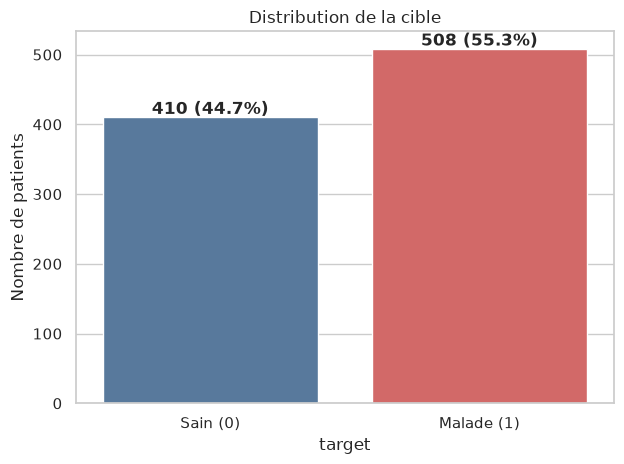

In [119]:
df['target'] = (df['num'] > 0).astype(int)    # 0 = sain, 1 = maladie
df = df.drop(columns='num')

counts = df['target'].value_counts().sort_index()
pct = (df['target'].value_counts(normalize=True).sort_index() * 100).round(1)
resume = pd.DataFrame({'effectif': counts, 'pourcentage_%': pct})
resume.index = ['Sain (0)', 'Malade (1)']
display(resume)

ax = sns.countplot(data=df, x='target', hue='target', palette=['#4C78A8','#E45756'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Sain (0)', 'Malade (1)'])
ax.set_title('Distribution de la cible')
ax.set_ylabel('Nombre de patients')
for i, (n, p) in enumerate(zip(counts, pct)):
    ax.text(i, n + 5, f'{int(n)} ({p:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


**🔎 Interprétation**
- **508 malades (55,3 %)** et **410 sains (44,7 %)** : les classes sont **assez équilibrées**. Pas besoin de rééquilibrage, et l'accuracy reste utilisable.
- Un modèle « bête » qui répondrait toujours « malade » aurait déjà **55 %** d'accuracy : c'est le **score minimal à battre**.

In [120]:
NUM = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

# les catégories sont converties en texte (les valeurs manquantes restent NaN)
for col in CAT:
    df[col] = df[col].map(lambda v: np.nan if pd.isna(v) else str(v))

## Phase 5 — Valeurs extrêmes (IQR) : diagnostic, aucune suppression

**Tâche** : repérer les valeurs hors de `[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]`, puis **décider** quoi en faire.
**Pourquoi sans code dédié** : les boxplots de la Phase 6 montrent déjà ces extrêmes ; le calcul n'aurait servi qu'à confirmer qu'**on ne supprime rien**.

| Variable | Hors bornes | Décision | Raison |
|---|---:|---|---|
| `age` | 0 | conserver | distribution bornée (28–77 ans) |
| `trestbps` | 27 | conserver | 200 mmHg correspond à une hypertension sévère réelle |
| `chol` | 23 | conserver | jusqu'à 603 mg/dL : hypercholestérolémie existante |
| `thalch` | 2 | conserver | fréquence cardiaque maximale basse = patient fragile |
| `oldpeak` | 16 | conserver | dépression du segment ST ; les valeurs négatives sont possibles |
| `ca` | 20 | conserver | variable **discrète** (0–3) : IQR = 0, la règle ne s'applique pas |

- **Aucune ligne n'est supprimée** : ces valeurs sont cliniquement plausibles et porteuses d'information (souvent les patients les plus malades).
- Le `StandardScaler` du `Pipeline` (Phase 9) limite leur influence sur la régression logistique ; les arbres y sont insensibles.
- Une **winsorisation** (plafonnement aux bornes) reste possible en variante, mais elle déformerait des mesures médicales réelles : elle n'est pas retenue.

## Phase 6 — Analyse visuelle

**Tâche** : distributions, boxplots par classe, taux de maladie par modalité.
**Pourquoi** : vérifier le nettoyage et voir la **forme** des relations avant de les quantifier (Phase 7).

**Tâche** : moyennes des variables numériques par classe.
**Pourquoi** : premier aperçu des différences entre sains et malades (Q1).

In [121]:
df.groupby("target")[NUM].mean().round(1)

,age,trestbps,chol,thalch,oldpeak,ca
target,,,,,,
0,50.6,130.0,240.2,148.8,0.4,0.3
1,55.9,134.2,254.1,128.3,1.3,1.1


**🔎 Interprétation**
- Les malades sont **plus âgés** (55,9 ans contre 50,6), ont une **fréquence cardiaque maximale plus basse** (`thalch` 128 contre 149), un **`oldpeak` plus élevé** (1,3 contre 0,4) et **plus de vaisseaux atteints** (`ca` 1,1 contre 0,3).
- `trestbps` (134 contre 130) et `chol` (254 contre 240) diffèrent **peu**.
- Les moyennes sont sensibles aux valeurs extrêmes : on vérifie avec des boxplots.

**Nom / lecture** : histogramme superposé + boxplot de l'âge par cible. Boîte = Q1–Q3, trait = médiane, points = valeurs extrêmes.


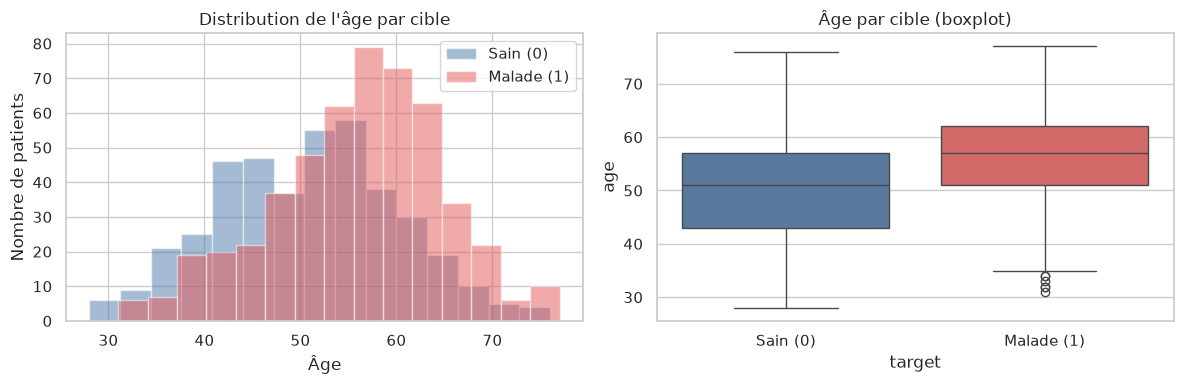

In [122]:
# Graphique : distribution de l'âge selon la cible
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t, label, color in [(0, "Sain (0)", "#4C78A8"), (1, "Malade (1)", "#E45756")]:
    subset = df.loc[df["target"] == t, "age"].dropna()
    axes[0].hist(subset, bins=15, alpha=0.5, label=label, color=color)
axes[0].set_title("Distribution de l'âge par cible")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre de patients")
axes[0].legend()

sns.boxplot(data=df, x="target", y="age", ax=axes[1], hue="target", palette=["#4C78A8", "#E45756"], legend=False)
axes[1].set_title("Âge par cible (boxplot)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sain (0)", "Malade (1)"])
plt.tight_layout()
plt.show()


**Nom / lecture** : 6 boxplots, un par variable numérique, séparés sains / malades. Deux boîtes décalées = variable discriminante ; fort chevauchement = variable peu informative seule.


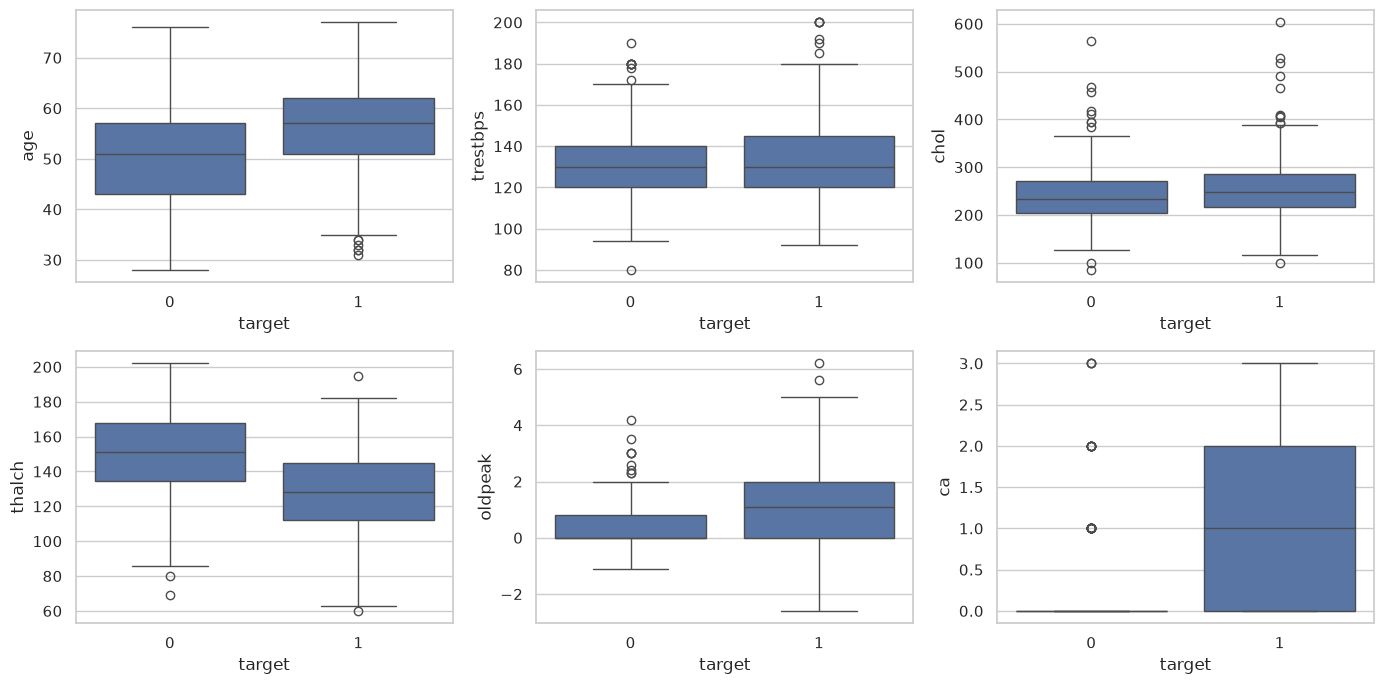

In [123]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
plt.tight_layout()
plt.show()

**Interprétation** : `thalch` plus bas chez les malades, `oldpeak` et `ca` plus élevés et mieux séparés ; `chol` et `trestbps` se chevauchent beaucoup.

**Tâche** : taux de maladie par modalité des variables catégorielles.
**Pourquoi** : repérer les catégories associées au risque (Q1).


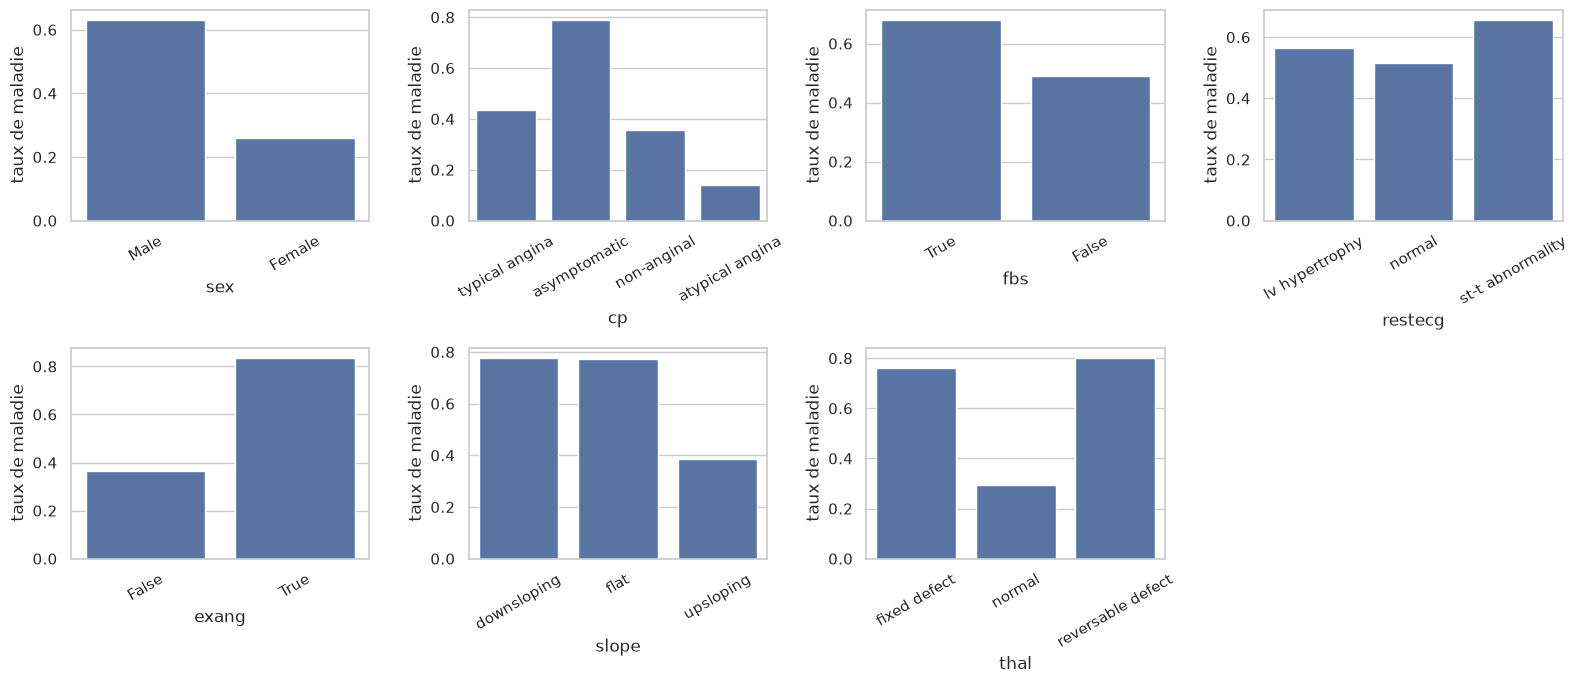

In [124]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), CAT):
    sns.barplot(data=df, x=col, y="target", ax=ax, errorbar=None)
    ax.set_ylabel("taux de maladie")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**🔎 Interprétation**
- **`cp`** : `asymptomatic` → **79 %** de malades, contre **14 %** pour `atypical angina`. Résultat contre-intuitif mais connu : l'absence de symptôme caractéristique accompagne souvent une maladie « silencieuse » dans ce jeu.
- **`exang`** (angine à l'effort) : **84 %** si oui, **36 %** si non.
- **`thal`** : 30 % si `normal`, contre ~80 % pour `reversable defect` et ~76 % pour `fixed defect`.
- **`slope`** : `upsloping` 38 %, contre ~77 % pour `flat` et `downsloping`.
- **`sex`** : 63 % des hommes contre 26 % des femmes.
- **`fbs`** 68 % contre 49 %, **`restecg`** 51 à 66 % : associations plus faibles.
- ⚠️ Prudence : l'échantillon est à 79 % masculin et mélange 4 centres, certains écarts peuvent venir de cette composition.


## Phase 7 — Étude des associations en 3 blocs séparés

**Tâche** : mesurer le lien entre les variables **sans mélanger les types**, puis classer les 13 variables selon leur association avec la maladie.

Une seule méthode ne peut pas couvrir les trois situations : on sépare donc les analyses.

| Bloc | Variables concernées | Mesure | Encodage ? |
|---|---|---|---|
| **7.1** | 6 numériques × 6 numériques | **r de Pearson** (−1 à +1) | non, ce sont des quantités |
| **7.2** | 7 catégorielles × 7 catégorielles | **V de Cramér** (0 à 1) | non, on garde les modalités |
| **7.3** | 6 numériques × 7 catégorielles | **eta η** (0 à 1) | non, comparaison de moyennes de groupes |
| **7.4** | les 13 variables × `target` | mesure adaptée au type + taux de malades par modalité | non |

**Règle retenue** : une variable catégorielle **n'entre jamais dans un calcul de Pearson** (ni dans un `astype(int)` de confort). Elle est analysée par V de Cramér ou eta, et n'est encodée (`OneHotEncoder`) qu'**après** le `train_test_split`, pour le modèle.

**Tâche** : prouver par l'exemple pourquoi une variable nominale ne passe pas par Pearson.
**Pourquoi** : si le coefficient change de signe selon l'ordre de numérotation, il ne mesure pas la maladie mais le codage.

In [125]:
# Même variable cp, trois façons de la coder en nombres : trois « corrélations » différentes
ordres = {
    "ordre alphabétique": sorted(df["cp"].dropna().unique()),
    "ordre clinique":     ["typical angina", "atypical angina", "non-anginal", "asymptomatic"],
    "autre ordre":        ["asymptomatic", "typical angina", "non-anginal", "atypical angina"],
}
pd.Series({nom: df["cp"].map({m: i for i, m in enumerate(o)}).corr(df["target"]) for nom, o in ordres.items()},
          name="Pearson(cp codé, target)").round(3).to_frame()

,"Pearson(cp codé, target)"
ordre alphabétique,-0.387
ordre clinique,0.471
autre ordre,-0.537


**Interprétation** : le même `cp` donne **−0,39**, **+0,47** ou **−0,54** selon l'ordre de numérotation, alors que les données sont identiques. Un tel coefficient n'a **aucun sens médical** : d'où le V de Cramér pour les catégorielles.

In [126]:
# Trois mesures, une par type de paire — aucune variable catégorielle n'est codée en nombre.
def cramers_v(x, y):
    """V de Cramér corrigé du biais (Bergsma) : 0 = aucun lien, 1 = lien parfait.
    Travaille directement sur les modalités (table de contingence), sans ordre imposé."""
    tab = pd.crosstab(x, y)                     # les paires incomplètes sont ignorées
    if tab.empty or min(tab.shape) < 2:
        return np.nan
    obs = tab.to_numpy()
    n = obs.sum()
    exp = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n
    phi2 = ((obs - exp) ** 2 / exp).sum() / n
    r, k = tab.shape
    phi2_c = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_c = r - ((r - 1) ** 2) / (n - 1)
    k_c = k - ((k - 1) ** 2) / (n - 1)
    denom = min(k_c - 1, r_c - 1)
    return np.sqrt(phi2_c / denom) if denom > 0 else np.nan


def eta(cat, num):
    """Rapport de corrélation eta (0 à 1) : part de la variance du numérique
    expliquée par les groupes de la catégorielle (eta² = cette part, au carré)."""
    d = pd.DataFrame({"groupe": cat, "valeur": num}).dropna()
    if d["groupe"].nunique() < 2 or d["valeur"].nunique() < 2:
        return np.nan
    g = d.groupby("groupe")["valeur"]
    ss_inter = (g.count() * (g.mean() - d["valeur"].mean()) ** 2).sum()
    ss_total = ((d["valeur"] - d["valeur"].mean()) ** 2).sum()
    return np.sqrt(ss_inter / ss_total) if ss_total > 0 else np.nan

### 7.1 — Numérique × numérique : Pearson

**Tâche** : mesurer la relation **linéaire** entre les 6 variables numériques (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `ca`) et repérer les redondances.
**Pourquoi Pearson ici et seulement ici** : `r` suppose deux **quantités** mesurées, avec une distance qui a un sens (5 ans d'écart = 5 ans). Il n'y a rien à encoder.

**Comment lire** : +1 même sens, −1 sens inverse, 0 pas de lien linéaire. Un `r` élevé entre deux features (|r| > 0,7) signalerait une redondance ; entre une feature et `target`, un signal utile.

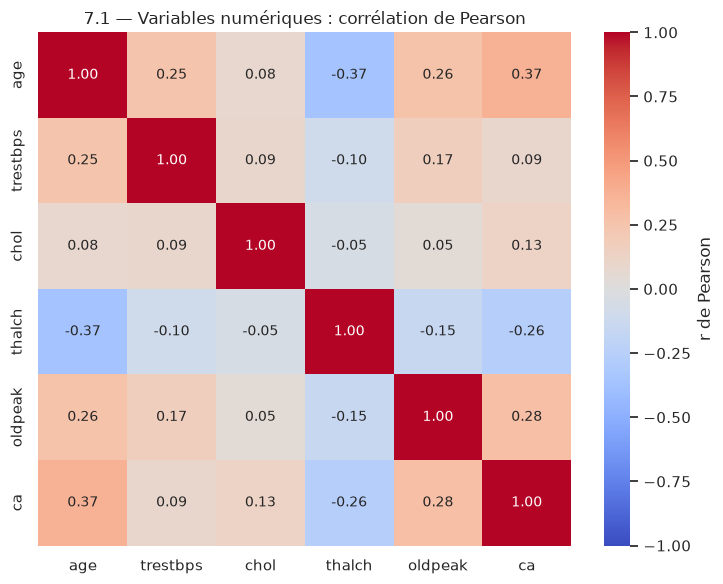

Paires numériques les plus liées (|r| décroissant) :
                  r de Pearson
age     ca               0.370
        thalch          -0.365
oldpeak ca               0.282
thalch  ca              -0.264
age     oldpeak          0.259
        trestbps         0.252


In [127]:
# 7.1 — Corrélation de Pearson entre variables NUMÉRIQUES (aucune catégorielle ici)
corr_num = df[NUM].corr(method="pearson")

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"label": "r de Pearson"})
plt.title("7.1 — Variables numériques : corrélation de Pearson")
plt.tight_layout()
plt.show()

# Paires les plus liées (triangle supérieur, classées par |r|)
triangle = np.triu(np.ones(len(NUM), dtype=bool), k=1)
paires_num = corr_num.where(triangle).stack()
paires_num = paires_num.reindex(paires_num.abs().sort_values(ascending=False).index)
print("Paires numériques les plus liées (|r| décroissant) :")
print(paires_num.head(6).round(3).to_frame("r de Pearson"))

**Interprétation 7.1 — Pearson**

| Paire | r | Lecture |
|---|---:|---|
| `age` – `ca` | **0,370** | plus on vieillit, plus on a de vaisseaux touchés |
| `age` – `thalch` | **−0,365** | la fréquence cardiaque maximale baisse avec l'âge (physiologique) |
| `oldpeak` – `ca` | 0,282 | un sous-décalage du segment ST plus marqué va avec plus de vaisseaux atteints |
| `thalch` – `ca` | −0,264 | moins de réserve cardiaque quand les vaisseaux sont touchés |
| `age` – `oldpeak` | 0,259 | — |
| `age` – `trestbps` | 0,252 | tension de repos un peu plus haute avec l'âge |

- **Aucune paire ne dépasse |r| = 0,40** : pas de redondance entre numériques, on garde les 6 variables.
- `age` est au centre de 4 des 6 paires : c'est un **facteur de confusion classique** (il pousse à la fois `ca`, `thalch` et `trestbps`). Le modèle devra donc être lu « à âge comparable ».
- ⚠️ Pearson ne voit que le **linéaire** : une relation en U passerait inaperçue. C'est pour cela qu'on complète par les deux blocs suivants et par les taux par catégorie (7.4).

### 7.2 — Catégorielle × catégorielle : V de Cramér

**Tâche** : mesurer l'association entre les 7 variables catégorielles (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`).
**Pourquoi pas Pearson** : `cp` codée 0-1-2-3 n'a ni ordre ni distance (démonstration ci-dessus). Le V de Cramér utilise la **table de contingence** des modalités, sans leur inventer une valeur numérique.
**Comment lire** : 0 = indépendance, 1 = lien parfait ; ordre de grandeur indicatif : < 0,10 négligeable · 0,10–0,30 faible · 0,30–0,50 modéré · ≥ 0,50 fort.

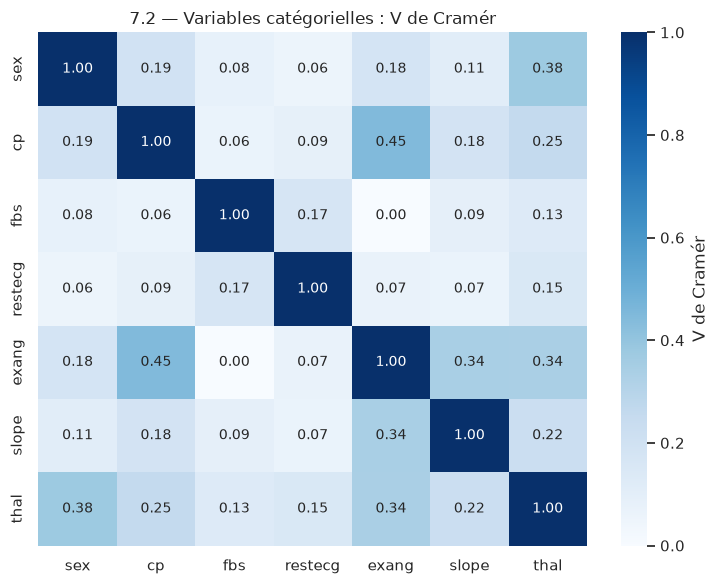

Paires catégorielles les plus associées :
             V de Cramér
cp    exang        0.447
sex   thal         0.375
exang slope        0.343
      thal         0.337
cp    thal         0.255
slope thal         0.225


In [128]:
# 7.2 — V de Cramér entre variables CATÉGORIELLES (modalités brutes, aucune conversion)
corr_cat = pd.DataFrame(
    [[1.0 if a == b else cramers_v(df[a], df[b]) for b in CAT] for a in CAT],
    index=CAT, columns=CAT, dtype=float,
)

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_cat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"label": "V de Cramér"})
plt.title("7.2 — Variables catégorielles : V de Cramér")
plt.tight_layout()
plt.show()

triangle_cat = np.triu(np.ones(len(CAT), dtype=bool), k=1)
paires_cat = corr_cat.where(triangle_cat).stack().sort_values(ascending=False)
print("Paires catégorielles les plus associées :")
print(paires_cat.head(6).round(3).to_frame("V de Cramér"))

**Interprétation 7.2 — V de Cramér**

| Paire | V | Lecture |
|---|---:|---|
| `cp` – `exang` | **0,447** | la douleur d'effort et l'angine d'effort décrivent en partie le même symptôme |
| `sex` – `thal` | 0,375 | l'anomalie de perfusion est plus fréquente chez les hommes de cette cohorte |
| `exang` – `slope` | 0,343 | l'angine d'effort va avec un segment ST anormal à l'effort |
| `exang` – `thal` | 0,337 | — |
| `cp` – `thal` | 0,255 | — |
| `exang` – `sex` | 0,176 | — |

- Toutes les paires restent **sous 0,50** : associations **modérées au plus**, aucune redondance à supprimer avant le split.
- Les paires fortes tournent autour de **l'effort** (`cp`, `exang`, `slope`, `thal`) : c'est cohérent cliniquement, ce sont quatre façons de décrire l'ischémie d'effort.
- ⚠️ Le V de Cramér **ne donne pas le sens** : il dit « lié », pas « plus de malades ». Le sens se lit dans les taux par modalité (7.4).

### 7.3 — Numérique × catégorielle : eta (η)

**Tâche** : mesurer si la valeur moyenne d'une variable numérique **change selon les modalités** d'une variable catégorielle (ex. : l'âge moyen diffère-t-il selon `cp` ?).
**Pourquoi eta** : on compare des **moyennes de groupes** sans transformer la catégorie en nombre ; c'est l'équivalent d'une ANOVA en intensité (0 à 1).
**Comment lire** : eta² = part de variance expliquée. η = 0,42 → ≈ 18 % de la variance du numérique est portée par les groupes.

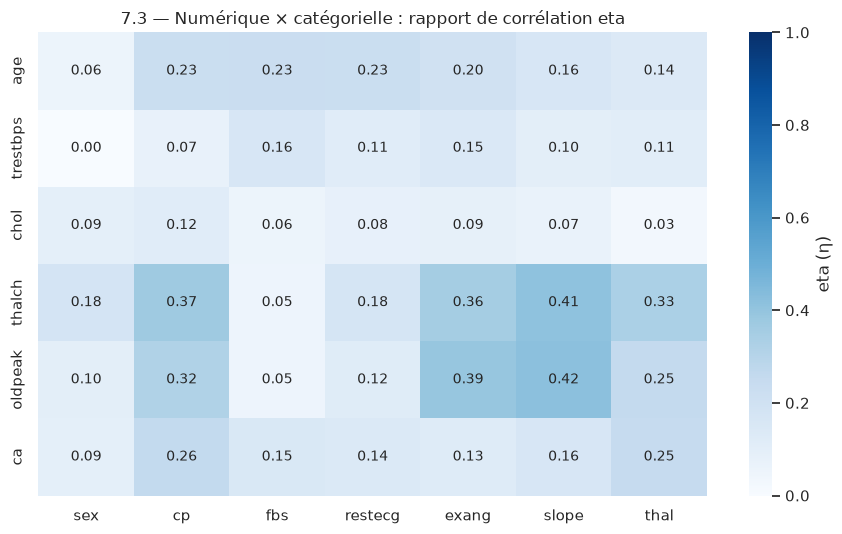

Couples numérique / catégorielle les plus liés :
                 eta
oldpeak slope  0.421
thalch  slope  0.410
oldpeak exang  0.394
thalch  cp     0.372
        exang  0.355
        thal   0.333
oldpeak cp     0.319
ca      cp     0.260


In [129]:
# 7.3 — eta entre chaque NUMÉRIQUE et chaque CATÉGORIELLE
assoc_num_cat = pd.DataFrame(
    [[eta(df[c], df[n]) for c in CAT] for n in NUM],
    index=NUM, columns=CAT, dtype=float,
)

plt.figure(figsize=(9, 5.5))
sns.heatmap(assoc_num_cat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            annot_kws={"size": 10}, cbar_kws={"label": "eta (η)"})
plt.title("7.3 — Numérique × catégorielle : rapport de corrélation eta")
plt.tight_layout()
plt.show()

paires_mixtes = assoc_num_cat.stack().sort_values(ascending=False)
print("Couples numérique / catégorielle les plus liés :")
print(paires_mixtes.head(8).round(3).to_frame("eta"))

**Interprétation 7.3 — eta**

| Couple | η | η² | Lecture |
|---|---:|---:|---|
| `oldpeak` – `slope` | **0,421** | 0,18 | le sous-décalage ST dépend fortement de la pente du segment ST |
| `thalch` – `slope` | **0,410** | 0,17 | la fréquence maximale atteinte diffère selon la pente |
| `oldpeak` – `exang` | 0,394 | 0,16 | — |
| `thalch` – `cp` | 0,372 | 0,14 | la fréquence maximale diffère selon le type de douleur |
| `thalch` – `exang` | 0,355 | 0,13 | — |
| `thalch` – `thal` | 0,333 | 0,11 | — |
| `oldpeak` – `cp` | 0,319 | 0,10 | — |
| `ca` – `cp` | 0,260 | 0,07 | — |

- Les liens mixtes les plus forts relient **`oldpeak`, `thalch` et `slope`/`exang`** : trois mesures de l'**effort**, donc partiellement redondantes. Le modèle peut les garder (η² ≤ 0,18), mais l'interprétation d'un coefficient seul doit rester prudente.
- Avec `chol` et `trestbps`, les η sont faibles (≤ 0,15) : ces mesures varient peu d'une catégorie à l'autre, ce qui n'empêche pas `chol` d'être utile au modèle (Phase 15).
- ⚠️ eta mesure une différence de **moyennes**, pas une relation causale, et ne voit pas les relations non monotones autres que par l'écart des groupes.

### 7.4 — Lien de chaque variable avec `target`

**Tâche** : classer les 13 variables selon leur association avec la maladie, **chacune avec la mesure de son type** (|Pearson| pour les numériques, V de Cramér pour les catégorielles), puis lire le **sens** dans les taux de malades par modalité.
**Pourquoi deux colonnes** : `target` est binaire ; on garde la même règle « pas de Pearson sur des catégories » et on affiche la base réelle de chaque calcul (les patients où la variable est connue).

In [130]:
# 7.4a — Association avec la cible : mesure adaptée au type, base de calcul affichée
explicatives = NUM + CAT
lien_cible = pd.DataFrame({
    "mesure": ["|Pearson|" if c in NUM else "V de Cramér" for c in explicatives],
    "association": [
        abs(df[[c, "target"]].corr().iloc[0, 1]) if c in NUM else cramers_v(df[c], df["target"])
        for c in explicatives
    ],
    "patients utilisés": [int(df[c].notna().sum()) for c in explicatives],
}, index=explicatives).sort_values("association", ascending=False).round(3)
display(lien_cible)

,mesure,association,patients utilisés
cp,V de Cramér,0.538,918
thal,V de Cramér,0.497,434
exang,V de Cramér,0.461,863
ca,|Pearson|,0.456,309
thalch,|Pearson|,0.393,863
oldpeak,|Pearson|,0.386,856
slope,V de Cramér,0.377,611
sex,V de Cramér,0.304,918
age,|Pearson|,0.282,918
fbs,V de Cramér,0.139,828


In [131]:
# 7.4b — Le chiffre dit « lié », pas « dans quel sens » : taux de malades par modalité
taux = []
for c in CAT:
    t = df.groupby(c)["target"].agg(["mean", "size"])
    for modalite, ligne in t.iterrows():
        taux.append({
            "variable": c,
            "modalité": modalite,
            "patients": int(ligne["size"]),
            "taux de malades %": round(100 * ligne["mean"], 1),
        })
taux_modalites = pd.DataFrame(taux).sort_values(["variable", "taux de malades %"], ascending=[True, False])
display(taux_modalites)

,variable,modalité,patients,taux de malades %
2,cp,asymptomatic,496,79.0
5,cp,typical angina,46,43.5
4,cp,non-anginal,203,35.5
3,cp,atypical angina,173,13.9
12,exang,True,336,83.6
11,exang,False,527,36.4
7,fbs,True,138,68.1
6,fbs,False,690,49.0
10,restecg,st-t abnormality,178,65.7
8,restecg,lv hypertrophy,188,56.4


**Interprétation 7.4 — ce qui est lié à la maladie**

**Classement (mesure adaptée au type) :**

| Rang | Variable | Mesure | Association | Patients utilisés |
|---|---|---:|---:|---:|
| 1 | `cp` | V de Cramér | **0,538** | 918 |
| 2 | `thal` | V de Cramér | **0,497** | 434 |
| 3 | `exang` | V de Cramér | **0,461** | 863 |
| 4 | `ca` | \|Pearson\| | **0,456** | 309 |
| 5 | `thalch` | \|Pearson\| | 0,393 | 863 |
| 6 | `oldpeak` | \|Pearson\| | 0,386 | 856 |
| 7 | `slope` | V de Cramér | 0,377 | 611 |
| 8 | `sex` | V de Cramér | 0,304 | 918 |
| 9 | `age` | \|Pearson\| | 0,282 | 918 |
| 10 | `fbs` | V de Cramér | 0,139 | 828 |
| 11 | `chol` | \|Pearson\| | 0,119 | 717 |
| 12 | `trestbps` | \|Pearson\| | 0,115 | 858 |
| 13 | `restecg` | V de Cramér | 0,100 | 916 |

**Sens médical (taux de malades par modalité)** : `cp = asymptomatic` **79,0 %** contre `atypical angina` 13,9 % · `exang = True` **83,6 %** contre 36,4 % · `thal = reversable defect` **80,2 %** et `fixed defect` 76,1 % contre `normal` 29,6 % · `slope = flat` 77,1 % / `downsloping` 77,8 % contre `upsloping` 38,4 % · `sex = Male` 63,2 % contre 25,9 % · `fbs = True` 68,1 % contre 49,0 % · `restecg` 51,5–65,7 % (écart faible, cohérent avec 0,100).

- **Les deux tiers du signal sont catégoriels** : `cp`, `thal`, `exang` occupent le podium, ce qu'une analyse limitée à Pearson aurait totalement manqué.
- ⚠️ **La colonne « patients utilisés » change la lecture** : `ca` (0,456) n'est calculé que sur **309 patients** (dont 299 de Cleveland) et `thal` sur 434 → associations **fragiles**, non représentatives des 4 centres.
- `chol` (0,119) et `trestbps` (0,115) sont faibles **linéairement**, mais `chol` ressort **2ᵉ en importance** dans le modèle (Phase 15) : association faible ≠ variable inutile.
- **Règle appliquée** : les catégories restent des catégories pendant tout l'EDA ; elles ne seront encodées (`OneHotEncoder`) qu'**après** le `train_test_split`, dans le pipeline, pour le modèle. Ces calculs portent sur les 918 patients **avant** le split : c'est de l'exploration, aucune variable n'est retirée.

**Pourquoi ne pas faire le One-Hot Encoding avant cette étude ?** (question de jury)

| Raison | Explication |
|---|---|
| **Fuite de données** | `OneHotEncoder` apprend la liste des modalités **sur les données qu'on lui donne**. Appliqué avant le `train_test_split`, il apprendrait des modalités présentes seulement dans le test : c'est de la fuite, et le test ne serait plus indépendant. |
| **Statistiques faussées** | Pearson sur des colonnes 0/1 issues du One-Hot écrase les coefficients (ils dépassent rarement 0,40 même pour un lien fort) et fabrique de **fausses corrélations négatives** entre modalités d'une même variable (`cp_asymptomatic` est mécaniquement anti-corrélé à `cp_non-anginal` : somme = 1). |
| **Matrice illisible** | 13 variables → ~26 colonnes 0/1 : une matrice 26 × 26 que personne ne peut lire en soutenance, pour un résultat moins juste. |

**La phrase à retenir** : *avant le split, on **observe** les variables brutes avec l'outil adapté à chaque type (Pearson / V de Cramér / eta) ; après le split, on **transforme** les catégorielles en One-Hot, appris sur `X_train` seulement, pour que le modèle puisse les utiliser.* C'est exactement ce que fait le pipeline de la Phase 9.

In [132]:
from sklearn.model_selection import train_test_split

X = df[NUM + CAT]     # informations du patient
y = df["target"]      # ce qu'on veut prédire

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("% malades -> train :", round(y_train.mean() * 100, 1), "| test :", round(y_test.mean() * 100, 1))

Train : (734, 13) | Test : (184, 13)
% malades -> train : 55.3 | test : 55.4


**🔎 Interprétation**
- **734 patients** pour l'entraînement, **184** pour le test.
- La proportion de malades est quasi identique (**55,3 %** et **55,4 %**) : le découpage est représentatif.
- Le jeu test sera **utilisé une seule fois**, à la fin, pour l'évaluation finale.

## Phase 9 — Préparation apprise sur le train

**Tâche** : médiane (numériques), mode (catégorielles), `StandardScaler`, `OneHotEncoder`, assemblés dans un `Pipeline`.
**Pourquoi** : même traitement appliqué au train, au test et à l'application ; chaque pli de la validation croisée réapprend ses propres statistiques (pas de fuite).

**Tâche** : comparer moyenne et médiane sur le train.
**Pourquoi** : choisir un remplacement robuste aux valeurs extrêmes.


In [133]:
X_train[NUM].agg(["mean", "median"]).round(1)

,age,trestbps,chol,thalch,oldpeak,ca
mean,53.6,132.3,247.6,137.7,0.9,0.7
median,54.0,130.0,240.0,140.0,0.5,0.0


**🔎 Interprétation**
- `chol` : moyenne **246,9** contre médiane **240** : l'écart vient des valeurs extrêmes (jusqu'à 603) qui tirent la moyenne.
- `oldpeak` : 0,9 contre 0,5, et `ca` : 0,6 contre 0 : ces distributions sont **asymétriques** (beaucoup de petites valeurs, quelques grandes).
- La **médiane** (valeur du milieu) n'est **pas influencée par les extrêmes** : c'est le choix le plus sûr pour remplacer un manquant.

In [134]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Statistiques apprises sur le TRAIN uniquement (pas sur le test)
imp_num = SimpleImputer(strategy="median")
imp_cat = SimpleImputer(strategy="most_frequent")
imp_num.fit(X_train[NUM])
imp_cat.fit(X_train[CAT])

print("Médianes apprises (train) :")
print(pd.Series(imp_num.statistics_, index=NUM).round(1))
print("\nModes appris (train) :")
print(pd.Series(imp_cat.statistics_, index=CAT))
print("\nManquants dans le train avant imputation :",
      int(X_train[NUM].isna().sum().sum()), "numériques /",
      int(X_train[CAT].isna().sum().sum()), "catégoriels")

Médianes apprises (train) :
age          54.0
trestbps    130.0
chol        240.0
thalch      140.0
oldpeak       0.5
ca            0.0
dtype: float64

Modes appris (train) :
sex                Male
cp         asymptomatic
fbs               False
restecg          normal
exang             False
slope              flat
thal             normal
dtype: str

Manquants dans le train avant imputation : 792 numériques / 734 catégoriels


**Interprétation** : médianes `age` 54, `trestbps` 130, `chol` **240**, `thalch` 140, `oldpeak` 0,5, `ca` 0 ; modes `sex` Male, `cp` asymptomatic, `fbs` False, `restecg` normal, `exang` False, `slope` flat, `thal` normal.

**Manquants** : **792 numériques** et **734 catégoriels** dans le train → 0 après imputation.

⚠️ `ca` manque à 66 % et devient 0 (« aucun vaisseau atteint ») pour des patients non examinés ; `thal` manque à 53 % et devient `normal` (la modalité au plus faible taux de maladie). C'est une hypothèse simplificatrice, d'où les **indicateurs de manquant** du pipeline : le modèle sait qu'une valeur a été inventée.

**Tâche** : assembler la préparation dans un `ColumnTransformer` + `Pipeline` (préparation + modèle).
**Pourquoi** : un seul objet à entraîner, à valider et à exporter ; impossible d'appliquer un traitement différent au test par erreur.


In [135]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])

def make(model):
    """Pipeline complet = préparation + modèle"""
    return Pipeline([("prep", prep), ("model", model)])

print("Colonnes après préparation :", make(None).named_steps["prep"].fit_transform(X_train).shape[1])

Colonnes après préparation : 30


**🔎 Interprétation**
- **30 colonnes** entrent dans le modèle : 6 numériques + 5 indicateurs de manquant (`trestbps`, `chol`, `thalch`, `oldpeak`, `ca`) + 19 colonnes One-Hot.
- La fonction `make(modèle)` permet d'essayer plusieurs modèles avec exactement la même préparation.

## Phase 10 — Valeurs manquantes : les 3 stratégies

`ca` (66 % manquants) et `thal` (53 %) sont les colonnes critiques. Trois solutions, **même split, même modèle RandomForest, même CV 5-fold** :

| Stratégie | Idée | Traitement de `ca` / `thal` |
|---|---|---|
| **1. Suppression** | retirer les colonnes trop incomplètes | colonnes supprimées (témoin « sans imputation ») |
| **2. Médiane / mode** | remplacer par une valeur typique | `ca` = médiane, `thal` = mode |
| **3. Patient similaire (KNN)** | copier la valeur des patients les plus proches | `KNNImputer`, distances sur variables **standardisées** |


In [136]:
# On réutilise X_train, X_test, y_train, y_test du split (Phase 8) : même split pour les 3 essais.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.impute import KNNImputer

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_rf():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
    ])


In [137]:
def eval_pipe(pipe, Xtr, ytr, Xte, yte):
    pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    proba = pipe.predict_proba(Xte)[:, 1]
    return {
        'Accuracy': accuracy_score(yte, pred),
        'Precision': precision_score(yte, pred, zero_division=0),
        'Recall': recall_score(yte, pred, zero_division=0),
        'F1-Score': f1_score(yte, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(yte, proba),
    }

def cv_pipe(pipe, X, y):
    scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {f'CV {k}': float(res[f'test_{k}'].mean()) for k in scoring}


In [138]:
# Expérience 1 — supprimer ca et thal
Xtr1 = X_train.drop(columns=['ca', 'thal'])
Xte1 = X_test.drop(columns=['ca', 'thal'])
num1 = [c for c in NUM if c != 'ca']
cat1 = [c for c in CAT if c != 'thal']

pipe1 = Pipeline([('pre', make_preprocessor(num1, cat1)), ('rf', make_rf())])
m1 = eval_pipe(pipe1, Xtr1, y_train, Xte1, y_test)
m1.update(cv_pipe(Pipeline([('pre', make_preprocessor(num1, cat1)), ('rf', make_rf())]), Xtr1, y_train))
m1


{'Accuracy': 0.8043478260869565,
 'Precision': 0.8,
 'Recall': 0.8627450980392157,
 'F1-Score': 0.8301886792452831,
 'ROC-AUC': 0.8986728837876614,
 'CV Accuracy': 0.8065697511881466,
 'CV Precision': 0.8109116436180791,
 'CV Recall': 0.854712436013249,
 'CV F1': 0.8311778264464185,
 'CV ROC-AUC': 0.8625628531861593}

In [139]:
# Expérience 2 — médiane pour les numériques, mode pour les catégorielles (solution actuelle)
pipe2 = Pipeline([('pre', make_preprocessor(NUM, CAT)), ('rf', make_rf())])
m2 = eval_pipe(pipe2, X_train, y_train, X_test, y_test)
m2.update(cv_pipe(Pipeline([('pre', make_preprocessor(NUM, CAT)), ('rf', make_rf())]), X_train, y_train))
m2


{'Accuracy': 0.8206521739130435,
 'Precision': 0.822429906542056,
 'Recall': 0.8627450980392157,
 'F1-Score': 0.8421052631578947,
 'ROC-AUC': 0.9132592061214729,
 'CV Accuracy': 0.8201938309570403,
 'CV Precision': 0.8293624013829947,
 'CV Recall': 0.8547124360132491,
 'CV F1': 0.8411451723743737,
 'CV ROC-AUC': 0.8756363510022046}

In [140]:
# Expérience 3 — imputation par patient similaire (KNN)
THAL_MAP = {'normal': 0, 'fixed defect': 1, 'reversable defect': 2}
THAL_INV = {v: k for k, v in THAL_MAP.items()}
SIM_NUM = [c for c in NUM if c != 'ca']
SIM_CAT = [c for c in CAT if c != 'thal']

def impute_similarity(X_fit, X_apply, n_neighbors=5):
    """Impute ca et thal avec les valeurs des patients les plus proches (KNN)."""
    num_imp = SimpleImputer(strategy='median').fit(X_fit[SIM_NUM])
    # Mise à l'échelle indispensable avant le calcul des distances :
    # sinon chol (~240) écrase complètement les indicatrices One-Hot (0/1)
    sc_num = StandardScaler().fit(num_imp.transform(X_fit[SIM_NUM]))
    cat_fill = X_fit[SIM_CAT].mode(dropna=True).iloc[0]
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_fit[SIM_CAT].fillna(cat_fill))

    def build(df):
        num = pd.DataFrame(sc_num.transform(num_imp.transform(df[SIM_NUM])), columns=SIM_NUM, index=df.index)
        cat = pd.DataFrame(ohe.transform(df[SIM_CAT].fillna(cat_fill)), columns=ohe.get_feature_names_out(SIM_CAT), index=df.index)
        ca = df[['ca']].astype(float)
        thal = df['thal'].map(THAL_MAP).rename('thal_code').to_frame()
        return pd.concat([num, cat, ca, thal], axis=1)

    A_fit = build(X_fit)
    A_apply = build(X_apply)
    knn = KNNImputer(n_neighbors=n_neighbors, weights='uniform').fit(A_fit)
    A_fit_imp = pd.DataFrame(knn.transform(A_fit), columns=A_fit.columns, index=A_fit.index)
    A_apply_imp = pd.DataFrame(knn.transform(A_apply), columns=A_apply.columns, index=A_apply.index)

    def restore(df_orig, A_imp):
        out = df_orig.copy()
        out['ca'] = A_imp['ca'].round().clip(0, 3).astype(float)
        codes = A_imp['thal_code'].round().clip(0, 2).astype(int)
        out['thal'] = codes.map(THAL_INV)
        out['ca_missing'] = df_orig['ca'].isna().astype(int)
        out['thal_missing'] = df_orig['thal'].isna().astype(int)
        return out

    return restore(X_fit, A_fit_imp), restore(X_apply, A_apply_imp)

def cv_similarity(X, y):
    rows = []
    for tr_idx, va_idx in cv.split(X, y):
        Xtr_imp, Xva_imp = impute_similarity(X.iloc[tr_idx], X.iloc[va_idx])
        pipe = Pipeline([('pre', make_preprocessor(NUM + ['ca_missing', 'thal_missing'], CAT)), ('rf', make_rf())])
        pipe.fit(Xtr_imp, y.iloc[tr_idx])
        pred = pipe.predict(Xva_imp)
        proba = pipe.predict_proba(Xva_imp)[:, 1]
        rows.append({
            'Accuracy': accuracy_score(y.iloc[va_idx], pred),
            'Precision': precision_score(y.iloc[va_idx], pred, zero_division=0),
            'Recall': recall_score(y.iloc[va_idx], pred, zero_division=0),
            'F1-Score': f1_score(y.iloc[va_idx], pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y.iloc[va_idx], proba),
        })
    cv_table = pd.DataFrame(rows).rename(columns={'F1-Score': 'F1'})
    return {f'CV {k}': float(cv_table[k].mean()) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}

Xtr3, Xte3 = impute_similarity(X_train, X_test)
pipe3 = Pipeline([('pre', make_preprocessor(NUM + ['ca_missing', 'thal_missing'], CAT)), ('rf', make_rf())])
m3 = eval_pipe(pipe3, Xtr3, y_train, Xte3, y_test)
m3.update(cv_similarity(X_train, y_train))
m3


{'Accuracy': 0.8478260869565217,
 'Precision': 0.8425925925925926,
 'Recall': 0.8921568627450981,
 'F1-Score': 0.8666666666666667,
 'ROC-AUC': 0.9116451458632232,
 'CV Accuracy': 0.8256360078277887,
 'CV Precision': 0.830658738082786,
 'CV Recall': 0.8645889792231255,
 'CV F1': 0.8465471430013303,
 'CV ROC-AUC': 0.8747279619908346}

In [141]:
# Tableau récapitulatif + classement selon le ROC-AUC test
results_cmp = pd.DataFrame({
    'Exp 1 — Supprimer ca/thal': m1,
    'Exp 2 — Médiane/mode (actuel)': m2,
    'Exp 3 — Patient similaire (KNN)': m3,
}).T

cols_show = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC',
             'CV Accuracy', 'CV Precision', 'CV Recall', 'CV F1', 'CV ROC-AUC']
results_cmp = results_cmp[[c for c in cols_show if c in results_cmp.columns]].round(4)
display(results_cmp)

print('\nClassement ROC-AUC (test) :')
print(results_cmp['ROC-AUC'].sort_values(ascending=False).to_string())


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Exp 1 — Supprimer ca/thal,0.8043,0.8000,0.8627,0.8302,0.8987,0.8066,0.8109,0.8547,0.8312,0.8626
Exp 2 — Médiane/mode (actuel),0.8207,0.8224,0.8627,0.8421,0.9133,0.8202,0.8294,0.8547,0.8411,0.8756
Exp 3 — Patient similaire (KNN),0.8478,0.8426,0.8922,0.8667,0.9116,0.8256,0.8307,0.8646,0.8465,0.8747



Classement ROC-AUC (test) :
Exp 2 — Médiane/mode (actuel)      0.9133
Exp 3 — Patient similaire (KNN)    0.9116
Exp 1 — Supprimer ca/thal          0.8987


In [142]:
# Analyse statistique simple : intervalle de confiance bootstrap du ROC-AUC
proba1 = pipe1.predict_proba(Xte1)[:, 1]
proba2 = pipe2.predict_proba(X_test)[:, 1]
proba3 = pipe3.predict_proba(Xte3)[:, 1]

def bootstrap_auc_ci(y_true, proba, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    idx = np.arange(len(y_true))
    aucs = []
    for _ in range(n_boot):
        b = rng.choice(idx, size=len(idx), replace=True)
        if len(np.unique(y_true[b])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[b], proba[b]))
    return np.percentile(aucs, [2.5, 97.5])

for nom, proba, yte in [
    ('Exp 1 — Supprimer ca/thal', proba1, y_test),
    ('Exp 2 — Médiane/mode (actuel)', proba2, y_test),
    ('Exp 3 — Patient similaire (KNN)', proba3, y_test),
]:
    lo, hi = bootstrap_auc_ci(yte, proba)
    print(f'{nom:35s} ROC-AUC = {roc_auc_score(yte, proba):.4f}  IC 95% = [{lo:.4f} ; {hi:.4f}]')


Exp 1 — Supprimer ca/thal           ROC-AUC = 0.8987  IC 95% = [0.8510 ; 0.9372]
Exp 2 — Médiane/mode (actuel)       ROC-AUC = 0.9133  IC 95% = [0.8718 ; 0.9492]
Exp 3 — Patient similaire (KNN)     ROC-AUC = 0.9116  IC 95% = [0.8691 ; 0.9498]


### Analyse des résultats et recommandation (PFE)

**Résultats obtenus (test + validation croisée 5-fold, `random_state=42`) :**

| Stratégie | Accuracy | Precision | Recall | F1 | ROC-AUC test | CV ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Exp 1 — Supprimer `ca`/`thal` | 0,8043 | 0,8000 | 0,8627 | 0,8302 | 0,8987 | 0,8626 |
| **Exp 2 — Médiane/mode (retenue)** | 0,8207 | 0,8224 | 0,8627 | 0,8421 | **0,9133** | **0,8756** |
| Exp 3 — Patient similaire (KNN) | **0,8478** | **0,8426** | **0,8922** | **0,8667** | 0,9116 | 0,8747 |

**Classement ROC-AUC test :** Exp 2 (0,9133) > Exp 3 (0,9116) > Exp 1 (0,8987).

**Lecture :**
- **Exp 2 (médiane/mode)** a le **meilleur ROC-AUC test** et le meilleur **CV ROC-AUC** : c'est la stratégie la plus performante et la plus stable.
- **Exp 3 (KNN / patient similaire)** a la meilleure **accuracy**, le meilleur **rappel** et le meilleur **F1** sur ce split : elle manque le moins de malades, mais elle est **derrière sur l'AUC** (0,9116 contre 0,9133) et **derrière en validation croisée** (0,8747 contre 0,8756). Son avantage porte donc sur le point de fonctionnement choisi (seuil 0,5), pas sur le pouvoir discriminant.
- **Exp 1 (suppression)** est la plus simple mais la moins performante partout. Elle reste utile comme témoin « sans imputation » : elle jette l'information de `ca` et `thal`, deux variables importantes.
- Les écarts sont **très faibles** et les **IC 95 % bootstrap se recoupent** : Exp 1 [0,851 ; 0,937], Exp 2 [0,872 ; 0,949], Exp 3 [0,869 ; 0,950]. Aucune supériorité statistiquement nette : pour un PFE, compléter par un test de DeLong ou plusieurs splits répétés avant d'affirmer une différence.

**Recommandation argumentée :**
1. **Retenir Exp 2 (médiane/mode)** : meilleur ROC-AUC test, meilleur CV ROC-AUC, **une seule valeur apprise par variable** (aucune dépendance à un voisinage), et surtout **c'est la stratégie effectivement exportée** dans `model.joblib` / l'application Streamlit. Cohérence totale entre ce que dit l'étude et ce que fait l'outil.
2. **Garder Exp 3 (KNN)** comme **variante « profil de patient »** : intéressante conceptuellement, mais elle exige de stocker tous les patients d'entraînement et devient fragile quand `ca` est manquant à 66 % (voisins calculés sur des valeurs imputées… donc proches de la médiane).
3. **Garder Exp 1 (suppression)** comme **témoin sans imputation** : simple, mais la plus faible et la plus coûteuse en information perdue.

**Point méthodologique important :** dans les distances du KNN, les variables sont **standardisées** (`StandardScaler`) avant le calcul des voisins. Sans cela, `chol` (~240) écraserait `oldpeak` (~0,5) et les voisins seraient choisis presque uniquement sur le cholestérol.

⚠️ **Limite des deux stratégies d'imputation :** remplacer un manquant par la médiane ou par le voisin le plus proche revient à **inventer une valeur**. C'est pourquoi le pipeline final ajoute des **indicateurs de manquant** (`add_indicator=True`) : le modèle sait « cette valeur a été inventée », et le seuil de décision (Phase 13) compense le biais résiduel en privilégiant le rappel.

## Phase 11 — Comparaison des modèles (validation croisée sur le train)

**Tâche** : comparer une baseline et 5 modèles avec la même préparation et la même CV 5-fold.
**Pourquoi** : un score sur un seul split est instable ; la CV donne une estimation plus fiable. Critère : **AUC**, complétée par le **rappel** (prioritaire en pré-dépistage).


In [143]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {
    "Baseline (toujours la classe majoritaire)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes = []
for nom, modele in models.items():
    auc = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    rappel = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="recall").mean()
    lignes.append({"modèle": nom, "AUC": round(auc, 3), "Rappel": round(rappel, 3)})

resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("AUC", ascending=False)
resultats

,AUC,Rappel
modèle,,
Régression logistique,0.883,0.852
Random Forest,0.876,0.857
KNN,0.864,0.847
Arbre de décision,0.804,0.786
Baseline (toujours la classe majoritaire),0.500,1.000


**🔎 Interprétation (Q4)**
- **Régression logistique** : meilleure AUC (**0,883**). **Random Forest** : très proche (**0,876**) avec un meilleur rappel (0,857). **KNN** : 0,864. **Arbre de décision** : 0,804, nettement moins bon (instable, il sur-apprend).
- **Baseline** : AUC **0,5** (le hasard). Son rappel de 1,0 est **trompeur** : elle répond toujours « malade », donc elle ne rate aucun malade mais se trompe sur tous les sains.
- L'écart entre régression logistique et forêt est **minime** (0,007) : les deux se valent. On retient la régression logistique, plus **simple et explicable** (un coefficient par variable, donc un discours clinique possible).

### Phase 11bis — Vérification avec 8 modèles (repris du notebook Kaggle « heart-disease-prediction-using-9-models »)

**Tâche :** rejouer la comparaison avec les familles de modèles utilisées dans la littérature Kaggle (SVM, Naive Bayes, AdaBoost, Gradient Boosting…).

**Ce qui est corrigé par rapport au notebook d'origine :**
- `LabelEncoder` sur des variables **nominales** (impose un ordre faux : `cp = 3` > `cp = 1`) → remplacé par le `OneHotEncoder` du `Pipeline` ;
- absence de **mise à l'échelle** (pénalisait KNN et SVM) → `StandardScaler` inclus dans le pipeline ;
- évaluation sur un seul découpage train/test → **validation croisée 5-fold** identique pour tous ;
- cible multi-classe (0–4) peu équilibrée → cible **binaire** conservée, cohérente avec le reste du notebook.

**XGBoost** (utilisé dans le notebook d'origine) n'est pas repris : il ajouterait une dépendance (`xgboost`) pour un gain non démontré sur 918 patients.


In [144]:
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Les 8 familles, toutes dans le MÊME pipeline (imputation + scaling + One-Hot)
modeles_etendus = {
    "Régression logistique": LogisticRegression(max_iter=2000),
    "SVM (noyau RBF)": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
}

lignes_etendues = []
for nom, modele in modeles_etendus.items():
    auc = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    rappel = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="recall").mean()
    lignes_etendues.append({"modèle": nom, "AUC": round(auc, 3), "Rappel": round(rappel, 3)})

resultats_etendus = (pd.DataFrame(lignes_etendues).set_index("modèle")
                     .sort_values("AUC", ascending=False))
resultats_etendus


,AUC,Rappel
modèle,,
Régression logistique,0.883,0.852
SVM (noyau RBF),0.879,0.869
Random Forest,0.876,0.857
AdaBoost,0.874,0.827
KNN,0.864,0.847
Gradient Boosting,0.862,0.825
Naive Bayes,0.857,0.813
Arbre de décision,0.804,0.786


**🔎 Interprétation**

| Modèle | AUC (CV) | Rappel (CV) |
|---|---:|---:|
| Régression logistique | **0,883** | 0,852 |
| SVM (noyau RBF) | 0,879 | **0,869** |
| Random Forest | 0,876 | 0,857 |
| AdaBoost | 0,874 | 0,827 |
| KNN | 0,864 | 0,847 |
| Gradient Boosting | 0,862 | 0,825 |
| Naive Bayes | 0,857 | 0,813 |
| Arbre de décision | 0,804 | 0,786 |

- **Aucune famille supplémentaire ne dépasse la régression logistique** en AUC : passer de 5 à 8 modèles ne change pas la décision.
- Le **SVM** obtient une AUC quasi identique (0,879) avec un meilleur rappel (0,869), mais il est écarté : moins **interprétable** (pas de coefficients lisibles) et plus coûteux à expliquer dans un mémoire.
- Les modèles d'ensembles (Random Forest, AdaBoost, Gradient Boosting) se tiennent dans **1,4 point d'AUC** : sur 734 patients d'entraînement, cet écart n'est pas significatif.
- **Conclusion** : la régression logistique reste le meilleur compromis performance / simplicité / explicabilité. Le choix ne repose donc pas sur un score unique mais sur un **ensemble d'arguments**.

**Tâche** : entraîner le modèle retenu sur tout le train, puis prédire sur le test (premier et unique usage du test).


In [145]:
meilleur = resultats.index[0]                      # meilleur AUC en validation croisée
final = make(models[meilleur]).fit(X_train, y_train)

proba = final.predict_proba(X_test)[:, 1]          # probabilité d'être malade
pred = final.predict(X_test)                       # classe prédite (seuil 0,5)
print("Modèle retenu :", meilleur)

Modèle retenu : Régression logistique


**🔎 Interprétation** : le modèle retenu est la **régression logistique**. Les variables `proba` (probabilités) et `pred` (classes) servent aux évaluations suivantes.

## Phase 12 — Évaluation sur le jeu test

**Tâche** : rapport de classification, AUC, métriques régressives (exigence VIC), matrice de confusion, courbe ROC.
**Pourquoi** : mesurer ce que le modèle donne sur des patients qu'il n'a jamais vus.


In [146]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, pred, target_names=["sain", "malade"]))
print("AUC :", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

        sain       0.86      0.78      0.82        82
      malade       0.84      0.90      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184

AUC : 0.927


**🔎 Interprétation (Q3)**
- **Accuracy 0,85** : 85 % de prédictions correctes (contre 55 % pour la baseline).
- **Classe « malade »** : précision **0,84**, rappel **0,90** : le modèle détecte **90 % des malades**.
- **Classe « sain »** : rappel **0,78** : il alerte à tort une part des sains (22 % des sains deviennent des fausses alertes).
- **AUC test = 0,927**, très proche de l'AUC en validation croisée (0,883) : pas de sur-apprentissage notable (le test est même légèrement plus facile).
- ⚠️ Le test ne compte que 184 patients (82 sains, 102 malades) : les chiffres sont fiables à quelques points près.

**Tâche** : calculer MAE, MSE et R² sur les probabilités et sur les classes.
**Pourquoi** : exigence du cahier des charges ; à interpréter avec prudence en classification.


In [147]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_true = y_test.values.astype(float)
y_prob = proba.astype(float)
y_pred_class = pred.astype(float)

# Sur les probabilités (recommandé) : le modèle sort une probabilité, on la compare à la classe 0/1
mae_prob = mean_absolute_error(y_true, y_prob)
mse_prob = mean_squared_error(y_true, y_prob)
rmse_prob = float(np.sqrt(mse_prob))
r2_prob = r2_score(y_true, y_prob)

# Sur la classe prédite (seuil 0,50)
mae_cls = mean_absolute_error(y_true, y_pred_class)
mse_cls = mean_squared_error(y_true, y_pred_class)
rmse_cls = float(np.sqrt(mse_cls))
r2_cls = r2_score(y_true, y_pred_class)

metrics_vic = pd.DataFrame({
    'Métrique': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Sur probabilité (recommandé)': [mae_prob, mse_prob, rmse_prob, r2_prob],
    'Sur classe prédite 0/1': [mae_cls, mse_cls, rmse_cls, r2_cls],
    'Interprétation': [
        'Erreur absolue moyenne : écart moyen entre probabilité prédite et classe réelle',
        'Erreur quadratique moyenne : pénalise fortement les erreurs confiantes',
        'Racine du MSE : même unité que la cible (ici une probabilité), donc lisible',
        'Part de variance expliquée : 1 = parfait, 0 = aussi bon que prédire la moyenne',
    ]
})
metrics_vic.round(4)

,Métrique,Sur probabilité (recommandé),Sur classe prédite 0/1,Interprétation
0,MAE,0.2317,0.1522,Erreur absolue moyenne : écart moyen entre pro...
1,MSE,0.1067,0.1522,Erreur quadratique moyenne : pénalise fortemen...
2,RMSE,0.3267,0.3901,Racine du MSE : même unité que la cible (ici u...
3,R²,0.5680,0.3840,"Part de variance expliquée : 1 = parfait, 0 = ..."


**Interprétation des résultats R² / MAE / MSE / RMSE** (test : 184 patients jamais vus)

| Métrique | Valeur (probabilité) | Valeur (classe 0/1) | Lecture |
|---|---:|---:|---|
| **MAE** | 0,2317 | 0,1522 | écart moyen de 0,23 entre la probabilité prédite et la réalité (0 ou 1) |
| **MSE** | 0,1067 | 0,1522 | pénalise les erreurs confiantes : prédire 0,95 pour un patient sain coûte cher |
| **RMSE** | 0,3267 | 0,3901 | racine du MSE : lisible dans l'unité de la cible (une probabilité) |
| **R²** | 0,5680 | 0,3840 | le modèle explique 57 % de la variance des étiquettes |

**Pourquoi ces métriques sont gardées** : elles sont exigées par le cahier des charges VIC, et elles ont un sens ici parce que le modèle **sort une probabilité** (nombre continu) comparable à la classe réelle 0/1. Sur la **classe prédite**, MAE et MSE mesurent simplement le taux d'erreur (0,1522 = 15,2 % d'erreurs) et le R² devient moins parlant.

### Rappel ou R² : quelle métrique est la plus importante ici ?

| | Rappel | R² |
|---|---|---|
| Ce qu'elle mesure | part des **malades réellement détectés** | part de **variance** des étiquettes expliquée |
| Ce qu'elle ignore | les fausses alertes (à compléter par la précision) | **le coût des erreurs** : malade manqué et sain alerté pèsent pareil |
| Si le score est mauvais | des malades rentrent chez eux non dépistés | le modèle est globalement peu informatif |
| Utilité ici | **décision opérationnelle** de triage | **contrôle méthodologique** et exigence du cours |

**Réponse claire : dans ce projet, c'est le RAPPEL qui pilote la décision ; le R² documente la qualité globale.**

1. Le problème est une **classification binaire de pré-dépistage** : un faux négatif a un coût humain, une fausse alerte un coût de temps. Le R² traite les deux erreurs **symétriquement**.
2. Le R² d'une classification binaire est **borné et peu parlant** (0,568 ici) : il ne dit pas combien de malades ont été manqués.
3. Le R² sert à **répondre au prof**, comparer les modèles et vérifier qu'on fait mieux que la moyenne (0,568 > 0), mais on ne choisit ni modèle ni seuil avec lui : on choisit avec le **rappel** (et l'AUC pour la discrimination), en affichant la précision pour ne pas devenir aveuglément alarmiste.

**Ordre de priorité retenu** : **rappel** (ne pas manquer de malades) → **AUC** (qualité de classement) → **précision / F1** (coût des fausses alertes) → **R², MAE, MSE, RMSE** (traçabilité et lecture d'erreur).

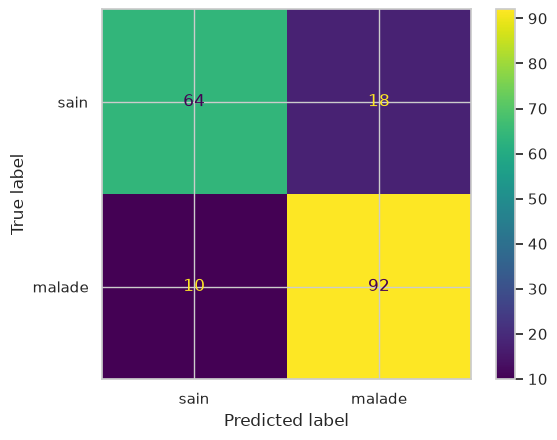

Faux négatifs (malades manqués) : 10 sur 102 malades
Faux positifs (sains alertés)   : 18 sur 82 sains


In [148]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["sain", "malade"])
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Faux négatifs (malades manqués) : {fn} sur {fn + tp} malades")
print(f"Faux positifs (sains alertés)   : {fp} sur {fp + tn} sains")

**🔎 Interprétation (Q5)**
- **10 faux négatifs sur 102 malades** (10 % de malades manqués).
- **18 faux positifs sur 82 sains** (22 % d'alertes inutiles).
- En médecine, manquer un malade est plus grave qu'une fausse alerte : on peut **déplacer le seuil de décision** (Phase 13).

**Tâche** : courbe ROC.


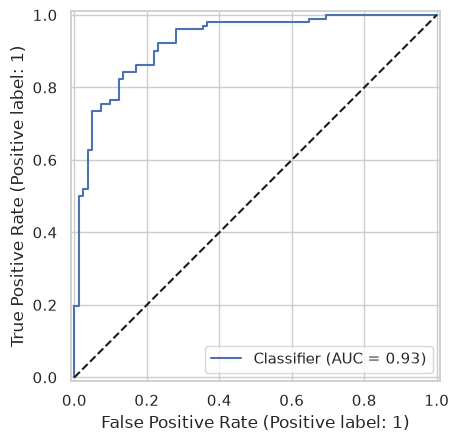

In [149]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, proba)
plt.plot([0, 1], [0, 1], "k--")       # ligne du hasard
plt.show()

**🔎 Interprétation**
- La courbe est **bien au-dessus de la diagonale** : le modèle sépare nettement mieux que le hasard.
- AUC 0,927 signifie qu'en tirant un malade et un sain au hasard, le modèle donne la **probabilité la plus haute au malade dans 93 % des cas**.
- Plus la courbe colle au coin supérieur gauche, meilleur est le compromis entre détection et fausses alertes.

### 12bis — Les 3 modèles comparés sur le test

**Tâche** : mêmes données, trois familles de modèles (régression logistique, Random Forest, KNN) : accuracy, précision, rappel, F1, AUC, faux négatifs et faux positifs.


In [ ]:
# 2) Calcul des matrices pour les 3 modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

modeles_cmp = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}

rows = []
cms = {}
for nom, m in modeles_cmp.items():
    m.fit(X_train, y_train)
    pred_m = m.predict(X_test)
    proba_m = m.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred_m)
    tn, fp, fn, tp = cm.ravel()
    cms[nom] = cm
    rows.append({'Modèle': nom,
                 'Accuracy': accuracy_score(y_test, pred_m),
                 'Précision': precision_score(y_test, pred_m, zero_division=0),
                 'Rappel': recall_score(y_test, pred_m, zero_division=0),
                 'F1': f1_score(y_test, pred_m, zero_division=0),
                 'AUC': roc_auc_score(y_test, proba_m),
                 'FN': fn, 'FP': fp})
cmp_df = pd.DataFrame(rows).set_index('Modèle')
cmp_df.round(4)


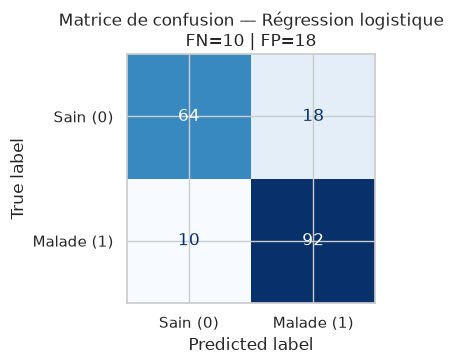

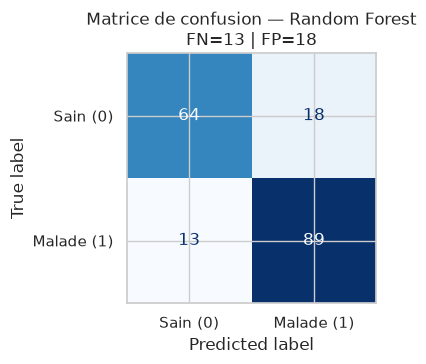

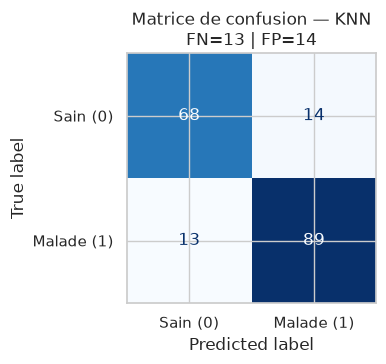

In [ ]:
# 3) Affichage des 3 matrices de confusion
for nom, cm in cms.items():
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=['Sain (0)', 'Malade (1)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'Matrice de confusion — {nom}\nFN={fn} | FP={fp}')
    plt.tight_layout()
    plt.show()


**Interprétation (3 modèles)**

| Modèle | Accuracy | Précision | Rappel | F1 | AUC | FN | FP |
|---|---:|---:|---:|---:|---:|---:|---:|
| Régression logistique | 0,848 | 0,836 | **0,902** | 0,868 | **0,927** | **10** | 18 |
| Random Forest | 0,832 | 0,832 | 0,873 | 0,852 | 0,917 | 13 | 18 |
| KNN | **0,853** | **0,864** | 0,873 | **0,868** | 0,898 | 13 | **14** |

- **Régression logistique** : meilleure AUC et **moins de malades manqués** (10 FN) → modèle retenu en pré-dépistage.
- **KNN** : meilleure accuracy et moins de fausses alertes, mais AUC plus faible et 3 malades manqués de plus.
- **Random Forest** : entre les deux, sans avantage décisif.
- FN = malade prédit sain (risque) ; FP = sain prédit malade (fausse alerte).

## Phase 13 — Seuil de décision

**Tâche** : choisir le seuil de probabilité qui garantit un **rappel ≥ 90 %**, à partir de probabilités **out-of-fold** du train (le test reste intact).
**Pourquoi** : 0,50 est une convention ; en pré-dépistage on accepte plus de fausses alertes pour manquer moins de malades.


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve

# probabilités "out-of-fold" sur le train (le test reste intact)
proba_cv = cross_val_predict(make(models[meilleur]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, seuils = roc_curve(y_train, proba_cv)

SEUIL = float(seuils[np.argmax(tpr >= 0.90)])      # premier seuil avec rappel >= 90 %
pred_seuil = (proba >= SEUIL).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_seuil).ravel()
print("Seuil choisi :", round(SEUIL, 2), "(au lieu de 0,50)")
print(f"Rappel : {tp / (tp + fn):.2f} | Faux négatifs : {fn} | Faux positifs : {fp}")

Seuil choisi : 0.41 (au lieu de 0,50)
Rappel : 0.92 | Faux négatifs : 8 | Faux positifs : 23


**🔎 Interprétation (Q5)**
- **Seuil de décision** : probabilité minimale pour classer un patient comme « malade (1) ». Par défaut 0,50 (50 %).
- **Seuil choisi ici : 0,41 (41 %)** — calculé automatiquement sur les prédictions **out-of-fold** du train pour obtenir un rappel ≥ 90 %.
- **Pourquoi 41 % et pas 50 % ?** En pré-dépistage, on préfère une fausse alerte à un malade manqué. Abaisser le seuil augmente le rappel (plus de malades détectés) mais baisse la précision (plus de fausses alertes).
- **Ce n'est pas un chiffre magique** : il dépend du jeu de données, du modèle et du compromis métier choisi.
- Sur le test : **rappel 0,92**, faux négatifs **10 → 8**, mais faux positifs **18 → 23**.
- **Compromis** : 2 malades supplémentaires détectés, au prix de 5 fausses alertes de plus. Pour un **dépistage**, ce choix est cohérent ; pour une **confirmation**, on privilégierait la précision.
- 8 malades restent manqués : le modèle n'est pas parfait, et c'est précisément pour cela que l'outil est une **aide à la décision**, pas un diagnostic.

## Phase 14 — Contrôle visuel : réel vs prédit

**Tâche** : placer chaque patient du test selon sa classe réelle et sa probabilité prédite, avec la ligne du seuil.


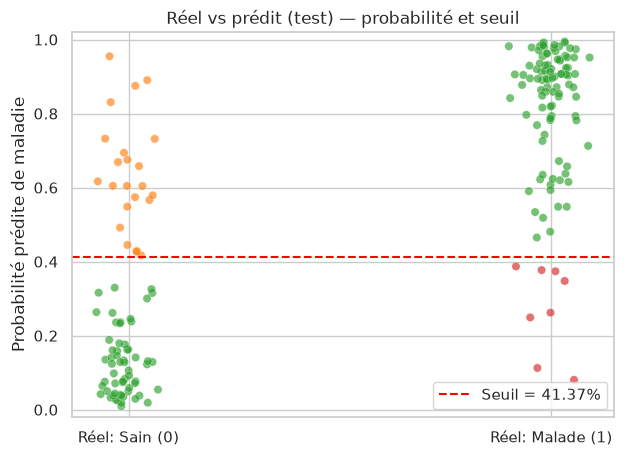

In [ ]:
yte = y_test.reset_index(drop=True)
proba_test = final.predict_proba(X_test)[:,1]
pred_test = (proba_test >= SEUIL).astype(int)
jitter = np.random.normal(0, 0.04, len(yte))
colors = np.where((yte.values==1)&(pred_test==0), '#d62728', np.where((yte.values==0)&(pred_test==1), '#ff7f0e', '#2ca02c'))
plt.figure(figsize=(7,5))
plt.scatter(yte.values + jitter, proba_test, c=colors, alpha=0.65, edgecolor='white', linewidth=0.3)
plt.axhline(SEUIL, color='red', linestyle='--', label=f'Seuil = {SEUIL:.2%}')
plt.xticks([0,1], ['Réel: Sain (0)', 'Réel: Malade (1)'])
plt.ylabel('Probabilité prédite de maladie')
plt.ylim(-0.02,1.02)
plt.title('Réel vs prédit (test) — probabilité et seuil')
plt.legend()
plt.show()


**Interprétation du graphique réel vs prédit**

**Ligne rouge (seuil)** : si la probabilité est au-dessus du seuil, le modèle prédit *Malade (1)* ; en dessous, il prédit *Sain (0)*.

Le graphique se lit en 4 zones :

| Zone | Position | Signification | Lecture |
|---|---|---|---|
| **Haut gauche** | Réel Sain (0), au-dessus ligne rouge | **Faux positif (FP)**, points orange | Sain prédit malade = fausse alerte. |
| **Bas gauche** | Réel Sain (0), sous ligne rouge | **Vrai négatif (TN)**, points verts | Sain bien prédit sain. |
| **Haut droite** | Réel Malade (1), au-dessus ligne rouge | **Vrai positif (TP)**, points verts | Malade bien détecté. |
| **Bas droite** | Réel Malade (1), sous ligne rouge | **Faux négatif (FN)**, points rouges | Malade prédit sain = dangereux, malade manqué. |

**Couleurs :** vert = prédiction correcte, orange = FP (fausse alerte), rouge = FN (malade manqué).

**Comment lire :** plus les points verts sont haut à droite et bas à gauche, mieux le modèle sépare. Les points rouges (bas droite) sont les plus critiques en pré-dépistage.

## Phase 15 — Importance des variables

**Tâche** : mesurer la contribution de chaque variable par **permutation** (on mélange une variable et on observe la baisse d'AUC).
**Pourquoi** : méthode valable pour tous les modèles, contrairement aux coefficients (linéaires seulement) et aux importances Gini (biaisées vers les variables à nombreuses modalités).


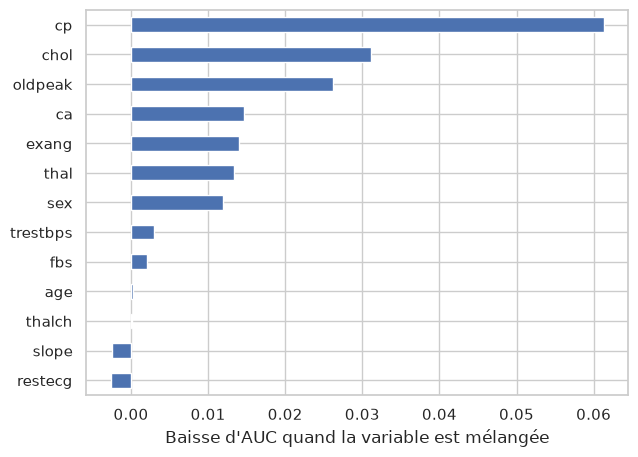

In [ ]:
from sklearn.inspection import permutation_importance

r = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42)
importance = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(7, 5))
plt.xlabel("Baisse d'AUC quand la variable est mélangée")
plt.show()

**Interprétation (importance des variables, Q2)**

Classement obtenu par permutation sur le jeu test (baisse d'AUC quand on mélange la variable) :

| Rang | Variable | Baisse d'AUC | Lecture |
|---|---|---:|---|
| 1 | `cp` | ≈ 0,061 | de très loin la plus utilisée par le modèle |
| 2 | `chol` | ≈ 0,031 | 2ᵉ malgré une corrélation linéaire faible (0,12) |
| 3 | `oldpeak` | ≈ 0,026 | dépression ST |
| 4 | `ca` | ≈ 0,013 | nombre de vaisseaux |
| 5 | `exang` | ≈ 0,012 | angine d'effort |
| 6 | `thal` | ≈ 0,012 | fixe |
| 7 | `sex` | ≈ 0,011 | |
| 8 | `trestbps` | ≈ 0,003 | quasi inutile |
| 9 | `fbs` | ≈ 0,002 | quasi inutile |
| 10 | `age`, `thalch` | ≈ 0,000 | redondants avec le reste du modèle |
| 11 | `slope`, `restecg` | **négatif** | bruit : les mélanger aide un peu |

- **`cp` domine** : la façon dont la douleur thoracique se présente est le signal principal.
- **`chol` en 2ᵉ position est le résultat le plus contre-intuitif** : sa corrélation avec la maladie n'est que de 0,12, mais le modèle s'en sert beaucoup en combinaison avec les autres variables (l'information utile est dans l'écart au cholestérol attendu, pas dans le cholestérol seul).
- **`age` et `thalch` à ≈ 0** ne veulent pas dire qu'ils sont inutiles médicalement : leur information est déjà portée par `ca`, `oldpeak` et `cp`. C'est de la **redondance**, pas de l'absence de signal.
- **Baisse négative** (`slope`, `restecg`) = variable **nuisible** au sens où la mélanger améliore légèrement l'AUC. Elle reste dans le modèle car le gain est dans le bruit de mesure, mais c'est un candidat à retirer dans une version suivante.
- ⚠️ Sur 184 patients de test, ces importances sont **indicatives** : un rééchantillonnage changerait l'ordre des rangs 4 à 7.

## Phase 16 — Prédiction sur de nouvelles données

**Tâche** : faire passer 3 profils types (faible risque, limite, risque élevé) dans le modèle retenu, puis comparer 3 modèles sur les mêmes données et sur un formulaire modifiable.
**Pourquoi** : simuler l'usage réel — un patient, une probabilité, une priorité.


In [ ]:
SCENARIOS = {
    "Profil faible risque": {
        "age": 42, "trestbps": 120, "chol": 210, "thalch": 170, "oldpeak": 0.0, "ca": 0.0,
        "sex": "Female", "cp": "non-anginal", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "upsloping", "thal": "normal"
    },
    "Profil vigilance (limite)": {
        "age": 55, "trestbps": 140, "chol": 245, "thalch": 145, "oldpeak": 1.0, "ca": 0.0,
        "sex": "Male", "cp": "atypical angina", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "flat", "thal": "normal"
    },
    "Profil risque élevé": {
        "age": 63, "trestbps": 150, "chol": 280, "thalch": 120, "oldpeak": 2.3, "ca": 2.0,
        "sex": "Male", "cp": "asymptomatic", "fbs": "True", "restecg": "lv hypertrophy",
        "exang": "True", "slope": "flat", "thal": "reversable defect"
    },
}

def predire_scenario(valeurs: dict, seuil_alerte: float = None):
    seuil = float(SEUIL) if seuil_alerte is None else float(seuil_alerte)
    ligne = pd.DataFrame([valeurs])[X_train.columns]
    proba = float(final.predict_proba(ligne)[0, 1])
    classe = "Malade (1)" if proba >= seuil else "Sain (0)"
    if proba >= seuil:
        niveau = "ALERTE – vérification humaine prioritaire"
    elif proba >= seuil / 2:
        niveau = "VIGILANCE – à surveiller"
    else:
        niveau = "NORMAL"
    return {"classe_predite": classe, "probabilite_malade": round(proba, 4), "seuil": round(seuil, 4), "niveau": niveau}

rows = []
for nom, vals in SCENARIOS.items():
    r = predire_scenario(vals)
    r = {"Scénario": nom, **r}
    rows.append(r)
pd.DataFrame(rows)


,Scénario,classe_predite,probabilite_malade,seuil,niveau
0,Profil faible risque,Sain (0),0.0123,0.4137,NORMAL
1,Profil vigilance (limite),Sain (0),0.0879,0.4137,NORMAL
2,Profil risque élevé,Malade (1),0.9959,0.4137,ALERTE – vérification humaine prioritaire


**Interprétation (réel attendu vs prédit) :**
- Chaque ligne = un cas saisi comme dans un formulaire (données patient).
- On compare les **3 modèles** sur les **mêmes données** : probabilité et prédiction au seuil de dépistage.
- **Concordance** entre modèles renforce la confiance ; **divergence** signale un cas limite/ambigu.
- `attendu_metier` est une attente de démonstration. En vrai contexte, la validation doit être faite par un professionnel de santé.

**Comment lire :** une probabilité élevée (> seuil) => classe "Malade (1)" ; faible => "Sain (0)". La différence entre modèles vient de leurs hypothèses (linéaire vs arbres vs voisins).


In [ ]:
# Comparaison sur les mêmes nouvelles données (formulaire) avec 3 modèles
# On utilise 3 modèles représentatifs entraînés sur X_train (sans fuite)
modeles_3 = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}
for name, m in modeles_3.items():
    m.fit(X_train, y_train)

# Données "formulaire" / nouvelles données (exemples réalistes)
nouvelles_donnees = pd.DataFrame([
    {'age':58,'trestbps':145,'chol':260,'thalch':135,'oldpeak':2.3,'ca':1.0,'sex':'Male','cp':'asymptomatic','fbs':'False','restecg':'normal','exang':'True','slope':'flat','thal':'reversable defect','attendu_metier':'Malade (1)'},
    {'age':42,'trestbps':120,'chol':210,'thalch':170,'oldpeak':0.0,'ca':0.0,'sex':'Female','cp':'typical angina','fbs':'False','restecg':'normal','exang':'False','slope':'upsloping','thal':'normal','attendu_metier':'Sain (0)'},
    {'age':55,'trestbps':135,'chol':245,'thalch':150,'oldpeak':1.0,'ca':0.0,'sex':'Male','cp':'atypical angina','fbs':'False','restecg':'normal','exang':'False','slope':'flat','thal':'normal','attendu_metier':'Cas limite'},
])

X_new = nouvelles_donnees.drop(columns=['attendu_metier'])
comparaison = nouvelles_donnees[['attendu_metier']].copy()
comparaison.insert(0, 'cas', [f'Patient {i+1}' for i in range(len(nouvelles_donnees))])

for name, m in modeles_3.items():
    p = m.predict_proba(X_new)[:,1]
    pred_c = (p >= SEUIL).astype(int)
    comparaison[f'{name} - proba_%'] = (p*100).round(2)
    comparaison[f'{name} - prédiction'] = np.where(pred_c==1,'Malade (1)','Sain (0)')

comparaison


,cas,attendu_metier,Régression logistique - proba_%,Régression logistique - prédiction,Random Forest - proba_%,Random Forest - prédiction,KNN - proba_%,KNN - prédiction
0,Patient 1,Malade (1),97.32,Malade (1),96.50,Malade (1),100.00,Malade (1)
1,Patient 2,Sain (0),1.57,Sain (0),7.83,Sain (0),0.00,Sain (0)
2,Patient 3,Cas limite,8.40,Sain (0),19.79,Sain (0),14.29,Sain (0)


**Interprétation** : les 3 modèles reçoivent exactement les mêmes données. Concordance = cas net ; divergence = cas limite à traiter avec prudence et avis humain.


In [ ]:
# Prédiction manuelle type formulaire (modifiable)
# Changez les valeurs ci-dessous pour tester un patient
patient_formulaire = pd.DataFrame([{
    'age': 60,
    'trestbps': 140,
    'chol': 250,
    'thalch': 130,
    'oldpeak': 1.5,
    'ca': 1.0,
    'sex': 'Male',
    'cp': 'asymptomatic',
    'fbs': 'False',
    'restecg': 'normal',
    'exang': 'True',
    'slope': 'flat',
    'thal': 'reversable defect',
}])

print('Données saisies (formulaire):')
display(patient_formulaire)

rows = []
for name, m in modeles_3.items():
    proba_m = float(m.predict_proba(patient_formulaire)[:,1][0])
    pred_m = int(proba_m >= SEUIL)
    rows.append({
        'Modèle': name,
        'Probabilité malade_%': round(proba_m*100,2),
        'Seuil_%': round(SEUIL*100,2),
        'Prédiction': 'Malade (1)' if pred_m==1 else 'Sain (0)',
        'Décision': '⚠️ Au-dessus du seuil' if pred_m==1 else '✅ Sous le seuil'
    })
resultat_formulaire = pd.DataFrame(rows)
resultat_formulaire


Données saisies (formulaire):


,age,trestbps,chol,thalch,oldpeak,ca,sex,cp,fbs,restecg,exang,slope,thal
0,60,140,250,130,1.5,1.0,Male,asymptomatic,False,normal,True,flat,reversable defect


,Modèle,Probabilité malade_%,Seuil_%,Prédiction,Décision
0,Régression logistique,96.33,41.37,Malade (1),⚠️ Au-dessus du seuil
1,Random Forest,94.67,41.37,Malade (1),⚠️ Au-dessus du seuil
2,KNN,85.71,41.37,Malade (1),⚠️ Au-dessus du seuil


**Interprétation** : le patient du formulaire est classé « à risque » par les 3 modèles (probabilités 0,96 / 0,95 / 0,86 au seuil 0,41) — cohérent avec son profil. Outil pédagogique, pas un diagnostic.


In [ ]:
# Tableau synthèse pour présentation VIC
synthese = pd.DataFrame({
    'Élément': ['Origine données','Nb observations','Nb variables','Cible','Split','Modèle retenu','AUC test','Rappel (seuil optimisé)','MAE (proba)','MSE (proba)','RMSE (proba)','R² (proba)'],
    'Valeur': [
        'UCI/Kaggle Heart Disease (4 centres)',
        f'{len(df)}',
        f'{df.shape[1]} (avant préparation: 16 colonnes brutes)',
        'target binaire: 1 si num>0 sinon 0',
        f'Train {len(X_train)} / Test {len(X_test)} stratifié',
        meilleur,
        f'{roc_auc_score(y_test, proba):.4f}',
        f'{tp/(tp+fn):.2f} au seuil {SEUIL:.2f}' if 'tp' in globals() else 'voir Phase 13',
        f'{mae_prob:.4f}',
        f'{mse_prob:.4f}',
        f'{rmse_prob:.4f}',
        f'{r2_prob:.4f}',
    ]
})
synthese


,Élément,Valeur
0,Origine données,UCI/Kaggle Heart Disease (4 centres)
1,Nb observations,918
2,Nb variables,14 (avant préparation: 16 colonnes brutes)
3,Cible,target binaire: 1 si num>0 sinon 0
4,Split,Train 734 / Test 184 stratifié
5,Modèle retenu,Régression logistique
6,AUC test,0.9267
7,Rappel (seuil optimisé),0.92 au seuil 0.41
8,MAE (proba),0.2317
9,MSE (proba),0.1067


## Phase 17 — Export du pipeline et application

**Tâche** : réentraîner le modèle sur **toutes** les données et sauvegarder le pipeline + ses métadonnées (seuil, bornes, catégories).
**Pourquoi** : l'évaluation est terminée, tous les patients peuvent servir ; l'application charge le modèle sans le réentraîner.


In [ ]:
import json, joblib

final_all = make(models[meilleur]).fit(X, y)       # réentraîné sur toutes les données
joblib.dump(final_all, "model.joblib")

meta = {
    "seuil": SEUIL,
    "num": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())} for c in NUM},
    "cat": {c: sorted(X[c].dropna().unique().tolist()) for c in CAT},
    "citation": "Janosi, Steinbrunn, Pfisterer & Detrano (1989). Heart Disease. UCI ML Repository. https://doi.org/10.24432/C52P4X (CC BY 4.0)",
}
json.dump(meta, open("model_meta.json", "w"), indent=2)
print("Fichiers créés : model.joblib, model_meta.json")

Fichiers créés : model.joblib, model_meta.json


**🔎 Interprétation** : deux fichiers sont créés : `model.joblib` (le pipeline complet) et `model_meta.json` (seuil, valeurs min/médiane/max, listes de catégories, citation de la source).

**Application Streamlit** : le fichier `app.py` du projet contient l'application complète (4 pages : Contexte, Processus ML, Prédiction, Notebook).
Pour la lancer : `streamlit run app.py`.

**Pourquoi** : l'application affiche un formulaire patient, calcule la **probabilité estimée**, la compare au seuil, et rappelle l'avertissement médical et la citation du jeu de données.


## Phase 18 — Conclusion

### Les deux questions qui reviennent le plus

**1) Quel est le meilleur modèle ?**

| Modèle | AUC CV | AUC test | Rappel (seuil 0,50) | Faux négatifs |
|---|---:|---:|---:|---:|
| **Régression logistique (retenue)** | **0,883** | **0,927** | **0,90** | **10 (8 au seuil 0,41)** |
| Random Forest | 0,876 | 0,917 | 0,87 | 13 |
| KNN | 0,864 | 0,898 | 0,87 | 13 |
| Arbre de décision | 0,804 | — | — | — |

➡️ **La régression logistique est le meilleur modèle** : meilleure AUC en validation croisée **et** sur le test, le meilleur rappel au seuil de dépistage retenu (8 malades manqués sur 102, contre 13 pour Random Forest et KNN), et le plus **explicable** (un coefficient par variable, donc un discours clinique possible). La vérification à 8 familles (Phase 11bis) ne change pas la conclusion.

**2) Valeurs manquantes : patient similaire (KNN) ou médiane/mode ?**

| Stratégie | ROC-AUC test | CV ROC-AUC | Complexité |
|---|---:|---:|---|
| **Médiane / mode (retenue)** | **0,9133** | **0,8756** | une valeur apprise par variable |
| Patient similaire (KNN) | 0,9116 | 0,8747 | stocke tous les patients, distances à calculer |
| Suppression de `ca` / `thal` | 0,8987 | 0,8626 | jette deux examens |

➡️ **La médiane / mode est la meilleure stratégie ici** : meilleur pouvoir discriminant (ROC-AUC test et CV), plus simple à expliquer et à déployer, et c'est **elle qui est exportée** dans `model.joblib` et l'application. Le KNN garde un meilleur rappel au seuil 0,50 mais **passe derrière** une fois les distances standardisées (sans standardisation, il écrasait les autres à tort), et il devient fragile parce que `ca` manque à 66 % : les voisins sont alors calculés sur des valeurs imputées, donc peu différents de la médiane.

➡️ **Limite honnête** : les IC bootstrap se recoupent (médiane [0,872 ; 0,949] vs KNN [0,869 ; 0,950]) — l'écart n'est **pas statistiquement démontré**. On choisit la médiane/mode pour sa **simplicité et sa cohérence avec l'outil livré**, pas pour une supériorité prouvée.


**Réponses aux questions de recherche**
- **Q1 — Facteurs associés à la maladie** (Phase 7 : Pearson pour les numériques, V de Cramér pour les catégorielles) : `cp` **0,538** (V de Cramér), `thal` **0,497**, `exang` **0,461**, `ca` **0,456** (\|Pearson\|, 309 patients seulement), `thalch` **0,393**, `oldpeak` **0,386**, `slope` 0,377, `sex` 0,304, `age` 0,282. Le facteur le plus lié est **catégoriel**, pas numérique. Les modalités à risque : `cp = asymptomatic` (79 % de malades), `exang = True` (84 %), `thal` anormal (~80 %), `slope` flat/downsloping (~77 %).
- **Q2 — Variables les plus contributives** (permutation, Phase 15) : `cp` très largement en tête (≈ 0,061 d'AUC), puis `chol` (≈ 0,031), `oldpeak` (≈ 0,026), `ca`, `exang`, `thal`, `sex`. `age` et `thalch` ressortent à ≈ 0 : leur information est déjà portée par les autres variables. `chol` est le cas le plus instructif : **11ᵉ** par corrélation, 2ᵉ par contribution — la corrélation seule ne suffit pas à juger de l'utilité d'une variable.
- **Q3 — Capacité prédictive** : **AUC 0,927** sur le test (CV 0,883), accuracy **0,848**, précision 0,836, rappel 0,902. Soit 156 bons pronostics sur 184 patients.
- **Q4 — Meilleur modèle** : la **régression logistique** (AUC CV 0,883), devant Random Forest (0,876), KNN (0,864) et l'arbre de décision (0,804) ; la vérification à 8 modèles ne change pas la conclusion (SVM 0,879, juste derrière, mais moins explicable). Pour les valeurs manquantes, l'étude comparative (Phase 10) place la **médiane/mode** en tête (ROC-AUC test **0,9133**, CV 0,8756), devant **patient similaire / KNN** (0,9116 / 0,8747) et **suppression** (0,8987 / 0,8626) ; les IC se recoupent, donc le classement est indicatif. La stratégie retenue est aussi celle qui est **exportée** dans l'application : pas de contradiction entre l'étude et l'outil.
- **Q5 — Fiabilité de la détection** : rappel **0,90** au seuil 0,5 (10 faux négatifs sur 102 malades, 18 faux positifs sur 82 sains). Avec le **seuil 0,41** choisi pour le pré-dépistage : rappel **0,92**, **8 faux négatifs**, 23 faux positifs. On échange 2 malades détectés en plus contre 5 fausses alertes en plus — arbitrage assumé pour du dépistage.

**Limites à citer dans le rapport**
- **Manquants massifs** : `ca` (66 %) et `thal` (53 %) sont imputés, donc **inventés**. La Phase 10 compare suppression, médiane/mode et KNN : les écarts sont faibles et les IC se recoupent, aucune supériorité n'est démontrée statistiquement.
- **Doublons** : 2 paires de lignes exactement identiques retirées (920 → 918). Elles ne changeaient pas les conclusions, mais les compter deux fois donnait un poids double à ces profils.
- **Centres hétérogènes** : le taux de maladie varie fortement selon le centre (36 % en Hongrie, 93 % en Suisse) et les manquants dépendent du centre : risque de raccourci géographique.
- **Échantillon** très masculin (79 %), données **anciennes** (1988), **aucune validation externe**, notamment pour une population tunisienne.
- **Test de 184 patients** : métriques, IC et importances sont **indicatifs** ; un autre découpage déplacerait les décimales.
- **Diagnostic ≠ risque futur** : le modèle ne prédit pas une crise cardiaque. C'est un **outil pédagogique, pas un avis médical**.


## Conclusion finale — le verdict

**Modèle retenu : régression logistique** (pipeline médiane/mode + scaling + one-hot, seuil 0,41).
**Valeurs manquantes : médiane / mode** (pas le patient le plus proche, pas la suppression).
**Usage : pré-dépistage** — aide à la décision, jamais un diagnostic.

### 1. Matrice de confusion réelle (test = 184 patients : 82 sains, 102 malades)

| Seuil | TN (sain → sain) | FP (sain → malade) | FN (malade → sain) | TP (malade → malade) | Accuracy | Rappel | Spécificité | Précision |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0,50 | 64 | 18 | 10 | 92 | 0,848 | 0,902 | 0,780 | 0,836 |
| **0,41 (retenu)** | 59 | 23 | **8** | **94** | 0,832 | **0,922** | 0,720 | 0,803 |

**Lecture** : sur 102 malades, le modèle en détecte **94** et en manque **8** (FN) ; sur 82 sains, **59** sont correctement rassurés (TN) et **23** reçoivent une fausse alerte (FP). Abaisser le seuil de 0,50 à 0,41 **échange 2 malades manqués contre 5 fausses alertes** — arbitrage assumé en pré-dépistage, puisqu'une alerte mène à un examen et qu'un malade manqué rentre chez lui.

- **TP/TN** = décisions correctes (**153/184** au seuil 0,41).
- **FP** = coût de temps et d'anxiété, jamais un risque vital direct.
- **FN** = l'erreur critique : 8 cas, tous visibles sur le graphique réel vs prédit (Phase 14).
- **VPN (TN/(TN+FN)) = 0,881 au seuil retenu** (0,865 au seuil 0,50) : quand le modèle dit « sain », il a raison ~88 % du temps — d'où l'avertissement médical obligatoire.

### 2. Métriques d'erreur et R² — ce qu'elles disent vraiment

| Métrique | Probabilité | Classe 0/1 | Interprétation |
|---|---:|---:|---|
| MAE | 0,2317 | 0,1522 | écart moyen de 0,23 entre la probabilité prédite et la réalité |
| MSE | 0,1067 | 0,1522 | pénalise les erreurs confiantes |
| RMSE | 0,3267 | 0,3901 | même unité qu'une probabilité, donc lisible |
| **R²** | **0,5680** | 0,3840 | **57 % de la variance des étiquettes expliquée** |

**Comment interpréter le R² = 0,568** : la cible est binaire, donc la variance à expliquer est celle d'une suite de 0 et de 1 — un R² ne peut **pas** approcher 1 dans ce cas, et 0,568 est une valeur **élevée** pour une classification (le plafond pratique tourne autour de 0,6). Concrètement : le modèle fait **nettement mieux que prédire la moyenne** (R² = 0 = pronostic constant), mais il reste 43 % de variance inexpliquée, ce qui est normal : il manque les facteurs non mesurés (tabac, antécédents familiaux, biologie fine). Sur la classe prédite, R² = 0,384 et MAE = MSE = 0,1522 (= taux d'erreur) : ces deux chiffres mesurent la même chose, l'erreur de décision.

**Ce que le R² ne dit pas** : combien de malades ont été manqués. Les deux erreurs y pèsent pareil. C'est pourquoi la décision se lit avec la **matrice de confusion + le rappel**, et le R² sert de **contrôle méthodologique** (exigence VIC, comparaison de modèles) : **rappel → AUC → précision/F1 → R²/MAE/MSE/RMSE**.

### 3. Pourquoi ces choix, en une phrase chacun

| Question | Réponse | Preuve |
|---|---|---|
| Meilleur modèle ? | **Régression logistique** | AUC CV **0,883** (devant RF 0,876, KNN 0,864, arbre 0,804), AUC test **0,927**, et 8 malades manqués au lieu de 13 |
| Meilleure imputation ? | **Médiane / mode** | ROC-AUC test **0,9133** > KNN 0,9116 > suppression 0,8987 ; plus simple et c'est la stratégie exportée |
| Pourquoi pas le patient le plus proche ? | KNN **fragile** ici | `ca` manque à 66 % : les voisins sont calculés sur des valeurs déjà inventées, et l'avantage disparaît après standardisation |
| Pourquoi pas supprimer `ca`/`thal` ? | **Perte d'information** | −0,015 d'AUC et deux examens jetés |
| Pourquoi le seuil 0,41 ? | **Rappel ≥ 90 % visé** | 8 FN au lieu de 10, au prix de 5 FP de plus |

### 4. Limites et suite

- 918 patients, **4 centres** aux pratiques différentes ; `ca` (309 connus) et `thal` (434) très incomplets.
- Données **rétrospectives** : le modèle décrit cette cohorte, il ne prouve pas une généralisation.
- Probabilités **non calibrées** : un 0,7 n'est pas exactement « 70 % de chances ».
- **Suite** : validation externe sur un autre hôpital, calibration (Brier / courbe de fiabilité), suivi de dérive.
- **Rappel de sécurité** : outil de **tri** pédagogique ; toute décision médicale revient à un professionnel.